# GPT-2 Beer correlation analysis

Grad-L2 saliency, FP-Growith, and hidden-state geometry for the `correlation1` Beer dataset.

The fine-tuned GPT-2 sequence classifier is `gpt2-beer-correlation1-seed42`. GPT-2 uses byte-level BPE, right-padding with EOS, causal attention, and no `[CLS]` or `[SEP]` tokens. Pattern representations use the last pattern token by default; mean pooling is available as a sensitivity analysis.

Place the checkpoint folder under `beer_models/` or set `MODEL_PATH_OVERRIDE` in the configuration cell. A GPU is recommended for Grad-L2 analysis.


## Beer correlation shortcut (`correlation1`)

### Expected shortcut for `correlation1`

The evaluation of an injected aroma description is correlated with the palate rating:

| Palate class | Rating | Injected aroma rating |
|---|---:|---:|
| 0 | 0.4 | 0.4 |
| 1 | 0.6 | 0.6 |
| 2 | 0.8 | 0.8 |
| 3 | 1.0 | 1.0 |

The analysis tests whether the classifier relies on evaluative aroma terms rather than palate-specific evidence. Negative descriptions are associated with class 0 and positive descriptions with class 3. These are hypotheses, not verified shortcut tokens.

FP-Growith identifies co-occurring token sets rather than necessarily contiguous n-grams. `ordered_ids` records one observed order for GPT-2 hidden-state extraction. Because GPT-2 is causal, the last token can attend to all preceding pattern tokens. A geometric shift alone does not establish causal shortcut reliance.


## S1 Vocabulary Construction

### Install / import dependencies

In [1]:
# Lightweight dependency bootstrap for a fresh Colab environment.
# Uses the same Transformers 4.x family as the GPT-2 fine-tuning notebook.
import importlib.util
import subprocess
import sys
_module_packages = {
    "transformers": "transformers>=4.46,<5",
    "datasets": "datasets>=2.18",
    "mlxtend": "mlxtend>=0.23",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "tqdm": "tqdm",
}
_missing = [pkg for mod, pkg in _module_packages.items()
            if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

from pathlib import Path
from collections import Counter, defaultdict
import subprocess
import os
import gc
import zipfile

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from datasets import Dataset
from transformers import (
    GPT2Model,
    GPT2TokenizerFast,
    GPT2ForSequenceClassification,
)
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from IPython.display import display


/Users/leosteiner/Desktop/transformer-shortcut-mitigation/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Configure paths and load pretrained / fine-tuned GPT-2

The fine-tuned classifier must come from **`correlation1`**. The pretrained reference is the untouched `gpt2` transformer. There is no independent pretrained classification head (its hypothetical logits are recorded as NaN).

In [2]:
# ---- Correlation only: edit this cell if your checkpoint is elsewhere ----
EXPERIMENT = "correlation1"
MODEL_SEED = 42
BASE_MODEL = "gpt2"
MAX_LENGTH = 512                        # Match GPT-2 Beer fine-tuning
PATTERN_POOLING = "last"               # "last" (recommended GPT-2) or "mean"
MODEL_PATH_OVERRIDE = None             # e.g. "/content/drive/MyDrive/beer_models/gpt2-beer-correlation1-seed42"
DATASET_PATH_OVERRIDE = None           # optional path to correlation1/dev.csv
PRED_BATCH_SIZE = 16
STATE_BATCH_SIZE = 16

if PATTERN_POOLING not in {"last", "mean"}:
    raise ValueError("PATTERN_POOLING must be 'last' or 'mean'")

PROJECT_ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd().resolve()
model_name = f"gpt2-beer-{EXPERIMENT}-seed{MODEL_SEED}"

# Optional: if the training notebook's saved beer_models.zip is uploaded
# into Colab /content, unpack it once. A custom archive name can be extracted manually.
for zip_name in ("beer_models.zip", "gpt2-beer-models.zip", "gpt2_beer_models.zip"):
    zip_file = PROJECT_ROOT / zip_name
    if zip_file.is_file() and not (PROJECT_ROOT / "beer_models" / model_name / "config.json").exists():
        with zipfile.ZipFile(zip_file) as archive:
            # Reject archive paths escaping the runtime directory.
            for member in archive.infolist():
                destination = (PROJECT_ROOT / member.filename).resolve()
                if not destination.is_relative_to(PROJECT_ROOT.resolve()):
                    raise ValueError(f"Unsafe ZIP path: {member.filename}")
            archive.extractall(PROJECT_ROOT)
        print("Unpacked checkpoint archive:", zip_file)

model_candidates = ([Path(MODEL_PATH_OVERRIDE).expanduser()] if MODEL_PATH_OVERRIDE else []) + [
    PROJECT_ROOT / "beer_models" / model_name,
    PROJECT_ROOT / model_name,
    Path.cwd() / "beer_models" / model_name,
    Path.cwd() / model_name,
]
model_path = next((p for p in model_candidates if (p / "config.json").is_file()), None)
if model_path is None:
    raise FileNotFoundError(
        f"Cannot locate fine-tuned GPT-2 checkpoint {model_name}. "
        f"Checked: {model_candidates}. Set MODEL_PATH_OVERRIDE to the unzipped checkpoint folder."
    )

# Dataset: support the original pipeline's local copy, or clone the source repo.
repo_root = PROJECT_ROOT / "shortcut-learning-in-text-classification"
dataset_candidates = ([Path(DATASET_PATH_OVERRIDE).expanduser()] if DATASET_PATH_OVERRIDE else []) + [
    PROJECT_ROOT / "beer_pipeline_datasets" / EXPERIMENT / "dev.csv",
    repo_root / "Dataset" / "beer_new" / "target" / "concept" / "split" / "correlation" / EXPERIMENT / "dev.csv",
]
dataset_path = next((p for p in dataset_candidates if p.is_file()), None)
if dataset_path is None:
    if not repo_root.exists():
        subprocess.run([
            "git", "clone", "--depth", "1",
            "https://github.com/yuqing-zhou/shortcut-learning-in-text-classification.git",
            str(repo_root)
        ], check=True)
    dataset_path = repo_root / "Dataset" / "beer_new" / "target" / "concept" / "split" / "correlation" / EXPERIMENT / "dev.csv"
if not dataset_path.is_file():
    raise FileNotFoundError(f"Cannot find correlation1 development data: {dataset_path}")

print("Fine-tuned GPT-2:", model_path)
print("Development data:", dataset_path)
print("Pattern pooling:", PATTERN_POOLING)

tokenizer = GPT2TokenizerFast.from_pretrained(str(model_path), local_files_only=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
# For GPT2ForSequenceClassification, padding MUST be on the right.
tokenizer.padding_side = "right"

ft_gpt2 = GPT2ForSequenceClassification.from_pretrained(str(model_path), local_files_only=True)
ft_gpt2.config.pad_token_id = tokenizer.pad_token_id
ft_gpt2.config.use_cache = False
assert ft_gpt2.config.num_labels == 4, "Expected four Beer palate classes"
assert ft_gpt2.config.model_type == "gpt2", "Wrong model architecture"

pt_gpt2 = GPT2Model.from_pretrained(BASE_MODEL)
pt_gpt2.config.use_cache = False
assert pt_gpt2.config.n_embd == ft_gpt2.config.n_embd
assert pt_gpt2.config.n_layer == ft_gpt2.config.n_layer == 12


Fine-tuned GPT-2: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/gpt2-beer-correlation1-seed42
Development data: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/beer_pipeline_datasets/correlation1/dev.csv
Pattern pooling: last


### Load the `correlation1` development split

In [3]:

df_dev = pd.read_csv(dataset_path).dropna(subset=["text", "label"]).copy()
df_dev["text"] = df_dev["text"].astype(str)

# Convert palate ratings to the classifier label IDs.
RATING_TO_ID = {0.4: 0, 0.6: 1, 0.8: 2, 1.0: 3}
ID_TO_RATING = {v: k for k, v in RATING_TO_ID.items()}
ratings = pd.to_numeric(df_dev["label"], errors="raise").round(1)
if set(ratings.unique()).issubset(RATING_TO_ID):
    df_dev["label"] = ratings.map(RATING_TO_ID).astype(int)
elif set(ratings.unique()).issubset({0, 1, 2, 3}):
    df_dev["label"] = ratings.astype(int)
else:
    raise ValueError(f"Unexpected Beer labels: {sorted(ratings.unique())}")

dev_data = Dataset.from_pandas(df_dev[["text", "label"]].reset_index(drop=True), preserve_index=False)
print("Dev reviews:", len(dev_data), "True class counts:", df_dev["label"].value_counts().sort_index().to_dict())


Dev reviews: 2000 True class counts: {0: 325, 1: 733, 2: 435, 3: 507}


### Select the Compute Devicee

In [4]:
# Prefer GPU; GPU makes the full Grad-L2 analysis practical.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

pt_gpt2 = pt_gpt2.to(device).eval()
ft_gpt2 = ft_gpt2.to(device).eval()
# Analysis is inference-only, except for gradients w.r.t. input embeddings.
# Disable weight gradients for significantly lower memory use.
for m in (pt_gpt2, ft_gpt2):
    for p in m.parameters():
        p.requires_grad_(False)

print("Device:", device)
if device.type == "cpu":
    print("Warning: this notebook will be very slow on CPU. Use your L4 GPU if available.")


Device: mps


### Grad-L2 saliency for GPT-2

Compute the L2 norm of the gradient of the **predicted-class logit** with respect to each input-token embedding, as in the original Beer pipeline and the GPT-2 IMDB notebook. The review is a single **unpadded** GPT-2 sequence; the classification head therefore uses the last token's hidden state.

There are no token-type IDs, `[CLS]` or `[SEP]` tokens. GPT-2's input embedding layer is `model.get_input_embeddings()` (`transformer.wte`).

In [5]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = MAX_LENGTH,
):
    """GPT-2 Grad-L2 saliency: tokens, norm per token, corresponding BPE token IDs."""
    model.eval()
    enc = tokenizer(
        text, return_tensors="pt", truncation=True,
        max_length=max_length, add_special_tokens=False,
    )
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    if input_ids.shape[1] == 0:
        raise ValueError("Empty GPT-2 token sequence: cannot calculate saliency")

    # Single, UNPADDED sequence. GPT-2's classification pooling of the last
    # position is therefore correct even when we pass inputs_embeds.
    with torch.no_grad():
        word_embeds = model.get_input_embeddings()(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)

    logits = model(
        inputs_embeds=word_embeds,
        attention_mask=attention_mask,
        return_dict=True,
    ).logits
    if target_class is None:
        target_class = int(logits.argmax(dim=-1).item())

    # Only input gradients; no parameter-gradient buffers are created.
    grads = torch.autograd.grad(logits[0, target_class], word_embeds)[0]
    saliency = grads.norm(p=2, dim=-1).squeeze(0).detach().float().cpu().numpy()
    token_ids = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(token_ids.tolist())
    return tokens, saliency, token_ids


### Predicted-Class Groups

The fine-tuned classifier assigns a predicted palate class to each development example. These predictions define four disjoint groups for class-specific saliency analysis and pattern mining.

In [6]:
def predict_labels(dataset_split, model, tokenizer, device,
                   batch_size=PRED_BATCH_SIZE, max_length=MAX_LENGTH):
    """Predict Beer classes from GPT-2's final non-padding token."""
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)
    predictions = []
    with torch.no_grad():
        for batch in tqdm(loader, desc="GPT-2 correlation1 dev predictions"):
            enc = tokenizer(
                list(batch["text"]), return_tensors="pt", truncation=True,
                padding=True, max_length=max_length, add_special_tokens=False,
            ).to(device)
            logits = model(**enc, return_dict=True).logits
            predictions.extend(logits.argmax(dim=-1).cpu().tolist())
    return predictions

# Never reuse BERT predictions: these groups are GPT-2-specific.
dev_preds = np.asarray(predict_labels(dev_data, ft_gpt2, tokenizer, device), dtype=np.int64)
class_indices = {c: np.flatnonzero(dev_preds == c).tolist() for c in range(4)}
print("Predicted class counts:")
for c, indices in class_indices.items():
    print(f"  Class {c} (palate {ID_TO_RATING[c]:.1f}): {len(indices)} reviews")
assert sum(len(indices) for indices in class_indices.values()) == len(dev_data)


GPT-2 correlation1 dev predictions: 100%|██████████| 125/125 [00:23<00:00,  5.38it/s]

Predicted class counts:
  Class 0 (palate 0.4): 357 reviews
  Class 1 (palate 0.6): 726 reviews
  Class 2 (palate 0.8): 395 reviews
  Class 3 (palate 1.0): 522 reviews


### Select the ten most salient **GPT-2 BPE token IDs** per review

For repeated token IDs, keep their maximum absolute Grad-L2 value. The ranking, token position, and normalization are otherwise unchanged.

In [7]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=10, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {}  # token_id -> (maximum absolute saliency, selected position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [{"token_id": tok_id, "saliency": a, "position": pos} for tok_id, a, pos in items]

### S1 Vocabulary Matrix

Each selected review is represented by a vocabulary-sized saliency vector. The entry for a token ID contains its maximum absolute Grad-L2 saliency within the review; all entries outside the top ten are set to zero. The vectors are stacked into a matrix and L2-normalized row by row.

Each row corresponds to a review, and each column corresponds to a GPT-2 byte-level BPE vocabulary item:

```text
          column dimension → |V| (S1 vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
```


In [8]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=10, exclude_special_ids=None):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # Allocate one entry per GPT-2 BPE vocabulary token.
    exclude_special_ids = set(exclude_special_ids or [])

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue
        r[tok_id] = max(r[tok_id], abs(float(s))) # Retain the maximum absolute saliency for each token ID.

    if top_k is not None and top_k < vocab_size:
        # Zero out all but the highest-scoring vocabulary entries.
        if np.count_nonzero(r) > top_k: # Apply sparsification only when more than top_k entries are nonzero.
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Select the indices of the top_k values.
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=10,
    max_length=512,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # Collect the selected text indices and token metadata.

    special_ids = tokenizer.all_special_ids  


    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k, exclude_special_ids=special_ids)
        R_rows.append(r)
        texts.append(text)


        # Record the highest-saliency position of each selected token ID.
        topk_vocab = topk_vocab_tokens_with_maxpos(
            ids, sal, top_k=top_k, exclude_special_ids=special_ids
        )
        salient_token_info.append({
            "dataset_idx": idx,
            "text": text,
            "topk_vocab": topk_vocab
        })

    R_vocab = np.stack(R_rows, axis=0)
    # L2-normalize each review-level S1 vector.
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    # Store raw and normalized saliency values for the selected tokens.
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"])              # Maximum absolute token saliency before row normalization.
            item["saliency_norm"] = float(R_vocab[row_i, tok_id])       # Corresponding entry in the row-normalized S1 matrix.

    return R_vocab, texts, salient_token_info

### Construct Four S1 Vocabulary Matrices

One row-normalized S1 matrix is constructed for each predicted class, using the ten most salient unique token IDs per review. All four matrices share the same GPT-2 BPE vocabulary. Each development example belongs to exactly one predicted-class group.

In [9]:
# Construct a top-10 S1 saliency matrix for each predicted class.
# Every development review contributes to its predicted-class group.
saliency_by_class = {}

for c in range(4):
    indices = class_indices[c]
    if not indices:
        raise ValueError(f"Predicted class {c} is empty; cannot mine this class")

    print(f"\nClass {c}, {len(indices)} reviews: computing top-10 Grad-L2 saliency")
    R_vocab, texts, salient_token_info = build_salience_vocab_matrix_from_indices(
        dev_data, indices, ft_gpt2, tokenizer, device, top_k=10
    )

    saliency_by_class[c] = {
        "R_vocab": R_vocab,
        "texts": texts,
        "salient_token_info": salient_token_info,
    }

print("\nFour S1 matrices constructed (one per class, top-10 only).")


Class 0, 357 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 357/357 [00:33<00:00, 10.50it/s]



Class 1, 726 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 726/726 [00:46<00:00, 15.76it/s]



Class 2, 395 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 395/395 [00:22<00:00, 17.83it/s]



Class 3, 522 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 522/522 [00:29<00:00, 17.44it/s]


Four S1 matrices constructed (one per class, top-10 only).


## Frequent Pattern Mining

FP-Growith is applied to the salient token sets of each predicted class.

### FP-Growith Support and Saliency Scoring

Each class is mined separately from transactions containing the ten selected token IDs per review. Patterns contain between one and four tokens and must occur in at least `MIN_SUPPORT_COUNT` reviews within their predicted-class group.

The resulting DataFrames include:

- `support`: fraction of reviews in the predicted-class group containing the pattern.
- `support_count`: number of supporting reviews in that group.
- `saliency_score`: mean normalized saliency of the pattern's tokens over supporting reviews.
- `score`: `support * saliency_score`.

FP-Growith identifies co-occurring token sets rather than necessarily contiguous n-grams. `ordered_ids` uses token positions from the first supporting review to provide one observed ordering.

In [10]:
MIN_SUPPORT_COUNT = 6  # Minimum supporting review count within each predicted class.
MAX_LEN = 4


def mine_frequent_itemsets(salient_token_info, class_id):
    # Construct per-review transactions and lookup tables.
    transactions = []
    pos_lookup = []
    saliency_lookup = []

    for item in salient_token_info:
        toks = [int(t["token_id"]) for t in item["topk_vocab"]]
        transactions.append(toks)
        pos_lookup.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})
        saliency_lookup.append({int(t["token_id"]): float(t["saliency_norm"]) for t in item["topk_vocab"]})

    n_rows = len(transactions)
    if n_rows < MIN_SUPPORT_COUNT:
        raise ValueError(f"Class {class_id} has only {n_rows} reviews; lower MIN_SUPPORT_COUNT")

    te = TransactionEncoder()
    X = te.fit(transactions).transform(transactions)
    df = pd.DataFrame(X, columns=te.columns_)

    freq_itemsets = fpgrowth(
        df,
        min_support=MIN_SUPPORT_COUNT / n_rows,
        use_colnames=True,
        max_len=MAX_LEN,
    )
    freq_itemsets["length"] = freq_itemsets["itemsets"].apply(len)

    # Recover token order from the first supporting review.
    def order_itemset_like_sentence(itemset):
        items = [int(x) for x in itemset]
        for tx, pm in zip(transactions, pos_lookup):
            if all(i in pm for i in items):
                return sorted(items, key=lambda i: pm[i])
        return items

    freq_itemsets["ordered_ids"] = freq_itemsets["itemsets"].apply(order_itemset_like_sentence)
    freq_itemsets["ordered_tokens"] = freq_itemsets["ordered_ids"].apply(
        lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
    )

    # Average normalized saliency over pattern tokens in supporting reviews.
    def pattern_saliency(itemset):
        items = [int(t) for t in itemset]
        scores = []
        for tx, sm in zip(transactions, saliency_lookup):
            if all(i in sm for i in items):
                for i in items:
                    scores.append(sm[i])
        return sum(scores) / len(scores) if scores else 0.0

    freq_itemsets["saliency_score"] = freq_itemsets["itemsets"].apply(pattern_saliency)
    freq_itemsets["score"] = freq_itemsets["support"] * freq_itemsets["saliency_score"]
    freq_itemsets["support_count"] = (freq_itemsets["support"] * n_rows).round().astype(int)
    freq_itemsets["predicted_class"] = class_id
    freq_itemsets["rating"] = ID_TO_RATING[class_id]
    freq_itemsets["top_k"] = 10

    return freq_itemsets


# Run FP-Growth independently for the four predicted classes.
freq_itemsets_by_class = {}
for c in range(4):
    info = saliency_by_class[c]["salient_token_info"]
    freq_itemsets_by_class[c] = mine_frequent_itemsets(info, class_id=c)
    print(f"Class {c}, top-10: {len(freq_itemsets_by_class[c])} frequent itemsets")

# Expose separate result DataFrames for class-specific inspection.
freq_itemsets_class0_10 = freq_itemsets_by_class[0]
freq_itemsets_class1_10 = freq_itemsets_by_class[1]
freq_itemsets_class2_10 = freq_itemsets_by_class[2]
freq_itemsets_class3_10 = freq_itemsets_by_class[3]


Class 0, top-10: 648 frequent itemsets
Class 1, top-10: 1345 frequent itemsets
Class 2, top-10: 779 frequent itemsets
Class 3, top-10: 1089 frequent itemsets


### Inspect Frequent Patterns by Predicted Class

The four DataFrames (`freq_itemsets_class0_10` through `freq_itemsets_class3_10`) contain all mined patterns of lengths one through four. Results can be filtered by pattern length and sorted by `support`, `support_count`, `saliency_score`, or `score`.

In [11]:
# Inspect single-token and unrestricted itemsets for predicted class 0.
freq_itemsets_class0_10[freq_itemsets_class0_10["length"] == 1].sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.
freq_itemsets_class0_10.sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.




,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
83,0.016807,(42905),1,[42905],[Ġoverpower],0.579019,0.009731,6,0,0.4,10
105,0.030812,(39145),1,[39145],[Ġfluffy],0.521663,0.016074,11,0,0.4,10
0,0.971989,(220),1,[220],[Ġ],0.460341,0.447447,347,0,0.4,10
150,0.462185,"(7888, 220)",2,"[7888, 220]","[Ġthin, Ġ]",0.455614,0.210578,165,0,0.4,10
569,0.019608,"(44560, 220)",2,"[44560, 220]","[Ġoily, Ġ]",0.454306,0.008908,7,0,0.4,10
619,0.022409,"(7888, 39145)",2,"[39145, 7888]","[Ġfluffy, Ġthin]",0.453322,0.010158,8,0,0.4,10
152,0.022409,"(7888, 6546)",2,"[6546, 7888]","[Ġthick, Ġthin]",0.437013,0.009793,8,0,0.4,10
90,0.019608,(44560),1,[44560],[Ġoily],0.436380,0.008556,7,0,0.4,10
628,0.016807,"(7888, 220, 285)",3,"[285, 7888, 220]","[Ġm, Ġthin, Ġ]",0.434338,0.007300,6,0,0.4,10
476,0.016807,"(5290, 220)",2,"[5290, 220]","[Ġworst, Ġ]",0.432977,0.007277,6,0,0.4,10


In [12]:
freq_itemsets_class1_10  # Predicted palate rating: 0.6.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.979339,(220),1,[220],[Ġ],0.393755,0.385619,711,1,0.6,10
1,0.176309,(4950),1,[4950],[Ġbeautiful],0.406546,0.071677,128,1,0.6,10
2,0.134986,(1312),1,[1312],[Ġi],0.224455,0.030298,98,1,0.6,10
3,0.126722,(3621),1,[3621],[Ġnice],0.321669,0.040762,92,1,0.6,10
4,0.020661,(7709),1,[7709],[Ġdecent],0.331335,0.006846,15,1,0.6,10
...,...,...,...,...,...,...,...,...,...,...,...
1340,0.012397,"(220, 11348)",2,"[11348, 220]","[Ġsour, Ġ]",0.345847,0.004287,9,1,0.6,10
1341,0.016529,"(23056, 220)",2,"[23056, 220]","[Ġrefreshing, Ġ]",0.359065,0.005935,12,1,0.6,10
1342,0.011019,"(23056, 764)",2,"[23056, 764]","[Ġrefreshing, Ġ.]",0.267296,0.002945,8,1,0.6,10
1343,0.011019,"(23056, 220, 764)",3,"[23056, 764, 220]","[Ġrefreshing, Ġ., Ġ]",0.327267,0.003606,8,1,0.6,10


In [13]:
freq_itemsets_class2_10  # Predicted palate rating: 0.8.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.989873,(220),1,[220],[Ġ],0.440658,0.436196,391,2,0.8,10
1,0.364557,(764),1,[764],[Ġ.],0.192010,0.069998,144,2,0.8,10
2,0.286076,(7090),1,[7090],[Ġmedium],0.321627,0.092010,113,2,0.8,10
3,0.215190,(7209),1,[7209],[Ġsmooth],0.476197,0.102473,85,2,0.8,10
4,0.025316,(39171),1,[39171],[Ġstout],0.231990,0.005873,10,2,0.8,10
...,...,...,...,...,...,...,...,...,...,...,...
774,0.020253,"(5796, 695)",2,"[5796, 695]","[sm, ell]",0.200837,0.004068,8,2,0.8,10
775,0.020253,"(220, 695)",2,"[695, 220]","[ell, Ġ]",0.377013,0.007636,8,2,0.8,10
776,0.020253,"(220, 5796, 695)",3,"[5796, 695, 220]","[sm, ell, Ġ]",0.324640,0.006575,8,2,0.8,10
777,0.020253,"(220, 532)",2,"[532, 220]","[Ġ-, Ġ]",0.272089,0.005511,8,2,0.8,10


In [14]:
freq_itemsets_class0_10.sort_values("support", ascending=False).head(40)  # Predicted palate rating: 0.4.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.971989,(220),1,[220],[Ġ],0.460341,0.447447,347,0,0.4,10
6,0.470588,(7888),1,[7888],[Ġthin],0.430024,0.202364,168,0,0.4,10
150,0.462185,"(7888, 220)",2,"[7888, 220]","[Ġthin, Ġ]",0.455614,0.210578,165,0,0.4,10
15,0.456583,(764),1,[764],[Ġ.],0.195761,0.089381,163,0,0.4,10
215,0.445378,"(220, 764)",2,"[764, 220]","[Ġ., Ġ]",0.355970,0.158541,159,0,0.4,10
1,0.316527,(5422),1,[5422],[Ġmouth],0.227421,0.071985,113,0,0.4,10
119,0.310924,"(220, 5422)",2,"[5422, 220]","[Ġmouth, Ġ]",0.352941,0.109738,111,0,0.4,10
216,0.238095,"(7888, 764)",2,"[764, 7888]","[Ġ., Ġthin]",0.317097,0.075499,85,0,0.4,10
217,0.232493,"(7888, 220, 764)",3,"[764, 7888, 220]","[Ġ., Ġthin, Ġ]",0.391268,0.090967,83,0,0.4,10
342,0.196078,"(220, 1660)",2,"[1660, 220]","[Ġwater, Ġ]",0.404549,0.079323,70,0,0.4,10


In [15]:
# Filter frequent patterns by number of tokens.
# Rank by normalized saliency, combined score, relative support, or count.
def inspect_patterns(predicted_class=3, size="all", sort_by="score", n=30):
    if predicted_class not in range(4):
        raise ValueError("predicted_class must be 0..3")
    if sort_by not in ("saliency_score", "score", "support", "support_count"):
        raise ValueError("Unsupported sort_by")

    result = freq_itemsets_by_class[predicted_class]
    if size == "single":
        result = result[result["length"] == 1]
    elif size == "multi":
        result = result[result["length"] >= 2]
    elif isinstance(size, int):
        result = result[result["length"] == size]
    elif size != "all":
        raise ValueError("size: 'all', 'single', 'multi', or integer 1..4")

    columns = ["ordered_tokens", "length", "support_count", "support", "saliency_score", "score"]
    return result.sort_values(sort_by, ascending=False).head(n)[columns]

# Display single-token patterns ranked by normalized saliency for each class.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | SINGLE TOKENS")
    display(inspect_patterns(c, size="single", sort_by="saliency_score", n=20))



CLASS 0 (palate 0.4) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
83,[Ġoverpower],1,6,0.016807,0.579019,0.009731
105,[Ġfluffy],1,11,0.030812,0.521663,0.016074
0,[Ġ],1,347,0.971989,0.460341,0.447447
90,[Ġoily],1,7,0.019608,0.436380,0.008556
16,[Ġcreamy],1,18,0.050420,0.432491,0.021806
6,[Ġthin],1,168,0.470588,0.430024,0.202364
59,[Ġopaque],1,6,0.016807,0.418460,0.007033
54,[Ġterrible],1,11,0.030812,0.407766,0.012564
92,[izzy],1,16,0.044818,0.391103,0.017528
94,[unky],1,15,0.042017,0.390773,0.016419



CLASS 1 (palate 0.6) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
205,[Ġbland],1,7,0.009642,0.577513,0.005568
124,[Ġthinner],1,19,0.026171,0.442285,0.011575
160,[Ġlovely],1,11,0.015152,0.439463,0.006659
32,[Ġthin],1,152,0.209366,0.434277,0.090923
131,[Ġfluffy],1,37,0.050964,0.419374,0.021373
51,[Ġimpressive],1,20,0.027548,0.417860,0.011511
182,[Ġcrisp],1,20,0.027548,0.411161,0.011327
1,[Ġbeautiful],1,128,0.176309,0.406546,0.071677
215,[apy],1,6,0.008264,0.406127,0.003356
176,[Ġbeautifully],1,6,0.008264,0.403746,0.003337



CLASS 2 (palate 0.8) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
89,[Ġcrisp],1,34,0.086076,0.476549,0.041019
3,[Ġsmooth],1,85,0.215190,0.476197,0.102473
32,[Ġbod],1,55,0.139241,0.473218,0.065891
82,[Ġnicely],1,9,0.022785,0.458831,0.010454
0,[Ġ],1,391,0.989873,0.440658,0.436196
14,[Ġcreamy],1,66,0.167089,0.438218,0.073221
15,[Ġthick],1,37,0.093671,0.411627,0.038557
73,[Ġlively],1,7,0.017722,0.407763,0.007226
18,[iness],1,6,0.015190,0.390784,0.005936
66,[Ġpleasing],1,6,0.015190,0.373397,0.005672



CLASS 3 (palate 1.0) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
26,[Ġsuperb],1,18,0.034483,0.471176,0.016247
0,[Ġ],1,517,0.990421,0.450115,0.445803
123,[Ġwonderfully],1,8,0.015326,0.443387,0.006795
5,[Ġexceptional],1,34,0.065134,0.443291,0.028873
38,[Ġcreamy],1,154,0.295019,0.431890,0.127416
9,[Ġdelicious],1,20,0.038314,0.429154,0.016443
124,[Ġlovely],1,10,0.019157,0.427607,0.008192
120,[Ġoily],1,6,0.011494,0.425028,0.004885
7,[Ġsmooth],1,172,0.329502,0.415984,0.137068
25,[Ġexcellent],1,37,0.070881,0.414263,0.029363


In [16]:
# Display multi-token patterns ranked by support-weighted saliency.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | MULTI-TOKEN")
    display(inspect_patterns(c, size="multi", sort_by="score", n=20))

# Additional class-specific pattern inspection queries.
# display(inspect_patterns(0, size="all", sort_by="support", n=40))
# display(inspect_patterns(3, size=2, sort_by="saliency_score", n=40))
# display(freq_itemsets_class2_10.sort_values("score", ascending=False).head(50))



CLASS 0 (palate 0.4) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
150,"[Ġthin, Ġ]",2,165,0.462185,0.455614,0.210578
215,"[Ġ., Ġ]",2,159,0.445378,0.355970,0.158541
119,"[Ġmouth, Ġ]",2,111,0.310924,0.352941,0.109738
217,"[Ġ., Ġthin, Ġ]",3,83,0.232493,0.391268,0.090967
342,"[Ġwater, Ġ]",2,70,0.196078,0.404549,0.079323
216,"[Ġ., Ġthin]",2,85,0.238095,0.317097,0.075499
353,"[y, Ġ]",2,58,0.162465,0.387841,0.063011
122,"[Ġthin, Ġmouth, Ġ]",3,55,0.154062,0.383197,0.059036
120,"[Ġthin, Ġmouth]",2,55,0.154062,0.349810,0.053892
123,"[Ġ., Ġmouth, Ġ]",3,51,0.142857,0.321409,0.045916



CLASS 1 (palate 0.6) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
265,"[Ġ., Ġ]",2,327,0.450413,0.315937,0.142302
516,"[Ġthin, Ġ]",2,148,0.203857,0.413306,0.084255
218,"[Ġbeautiful, Ġ]",2,128,0.176309,0.401640,0.070813
757,"[Ġmouth, Ġ]",2,118,0.162534,0.301469,0.048999
225,"[Ġi, Ġ]",2,97,0.133609,0.357130,0.047716
768,"[Ġcreamy, Ġ]",2,96,0.132231,0.360617,0.047685
240,"[Ġnice, Ġ]",2,92,0.126722,0.346086,0.043857
705,"[Ġthick, Ġ]",2,83,0.114325,0.354845,0.040568
843,"[Ġ:, Ġ]",2,86,0.118457,0.323402,0.038309
316,"[Ġcarbon, Ġ]",2,82,0.112948,0.325791,0.036797



CLASS 2 (palate 0.8) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
117,"[Ġ., Ġ]",2,142,0.359494,0.320506,0.115220
218,"[Ġmouth, Ġ]",2,131,0.331646,0.342734,0.113666
118,"[Ġmedium, Ġ]",2,112,0.283544,0.388555,0.110173
125,"[Ġsmooth, Ġ]",2,85,0.215190,0.439186,0.094508
562,"[Ġcarbon, Ġ]",2,98,0.248101,0.353200,0.087629
146,"[Ġnice, Ġ]",2,88,0.222785,0.380624,0.084797
221,"[Ġcreamy, Ġ]",2,66,0.167089,0.431572,0.072111
321,"[Ġgood, Ġ]",2,75,0.189873,0.368522,0.069973
466,"[Ġbod, Ġ]",2,55,0.139241,0.449222,0.062550
355,"[Ġbody, Ġ]",2,57,0.144304,0.360569,0.052031



CLASS 3 (palate 1.0) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
158,"[Ġ., Ġ]",2,216,0.413793,0.344699,0.142634
210,"[Ġsmooth, Ġ]",2,170,0.325670,0.431497,0.140526
424,"[Ġcreamy, Ġ]",2,153,0.293103,0.430578,0.126204
159,"[Ġperfect, Ġ]",2,111,0.212644,0.417140,0.088702
431,"[Ġmouth, Ġ]",2,135,0.258621,0.313274,0.081019
227,"[Ġthick, Ġ]",2,72,0.137931,0.384640,0.053054
360,"[Ġcarbon, Ġ]",2,76,0.145594,0.345664,0.050327
427,"[Ġcreamy, Ġsmooth, Ġ]",3,57,0.109195,0.407785,0.044528
425,"[Ġcreamy, Ġsmooth]",2,57,0.109195,0.396589,0.043306
303,"[Ġaroma, Ġ]",2,67,0.128352,0.335917,0.043116


## Experiment 1: Saliency, Support, and Embedding Changes

### Select the Class for Experiment 1

`CLASS_FOR_EXPERIMENT1` determines which predicted-class patterns are used in the plots and embedding comparisons. The four FP-Growith result DataFrames are retained independently. The `two_grams` variable contains up to 100 frequent multi-token patterns from the selected class.

In [17]:
CLASS_FOR_EXPERIMENT1 = 3  # Predicted class used for Experiment 1 visualizations.

two_grams = (
    freq_itemsets_by_class[CLASS_FOR_EXPERIMENT1]
    .query("length > 1")
    .sort_values("score", ascending=False)
    .head(100)
    .copy()
)
print(f"Experiment 1: predicted class {CLASS_FOR_EXPERIMENT1}, {len(two_grams)} multi-token itemsets")
display(two_grams.head(20))

if two_grams.empty:
    raise ValueError("No multi-token patterns for Experiment 1 class. Check MIN_SUPPORT_COUNT / predicted-class support")


Experiment 1: predicted class 3, 100 multi-token itemsets


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
158,0.413793,"(220, 764)",2,"[764, 220]","[Ġ., Ġ]",0.344699,0.142634,216,3,1.0,10
210,0.325670,"(7209, 220)",2,"[7209, 220]","[Ġsmooth, Ġ]",0.431497,0.140526,170,3,1.0,10
424,0.293103,"(220, 27892)",2,"[27892, 220]","[Ġcreamy, Ġ]",0.430578,0.126204,153,3,1.0,10
159,0.212644,"(2818, 220)",2,"[2818, 220]","[Ġperfect, Ġ]",0.417140,0.088702,111,3,1.0,10
431,0.258621,"(220, 5422)",2,"[5422, 220]","[Ġmouth, Ġ]",0.313274,0.081019,135,3,1.0,10
227,0.137931,"(6546, 220)",2,"[6546, 220]","[Ġthick, Ġ]",0.384640,0.053054,72,3,1.0,10
360,0.145594,"(220, 6588)",2,"[6588, 220]","[Ġcarbon, Ġ]",0.345664,0.050327,76,3,1.0,10
427,0.109195,"(7209, 220, 27892)",3,"[27892, 7209, 220]","[Ġcreamy, Ġsmooth, Ġ]",0.407785,0.044528,57,3,1.0,10
425,0.109195,"(7209, 27892)",2,"[27892, 7209]","[Ġcreamy, Ġsmooth]",0.396589,0.043306,57,3,1.0,10
303,0.128352,"(31242, 220)",2,"[31242, 220]","[Ġaroma, Ġ]",0.335917,0.043116,67,3,1.0,10


### Plot Pattern Saliency and Support

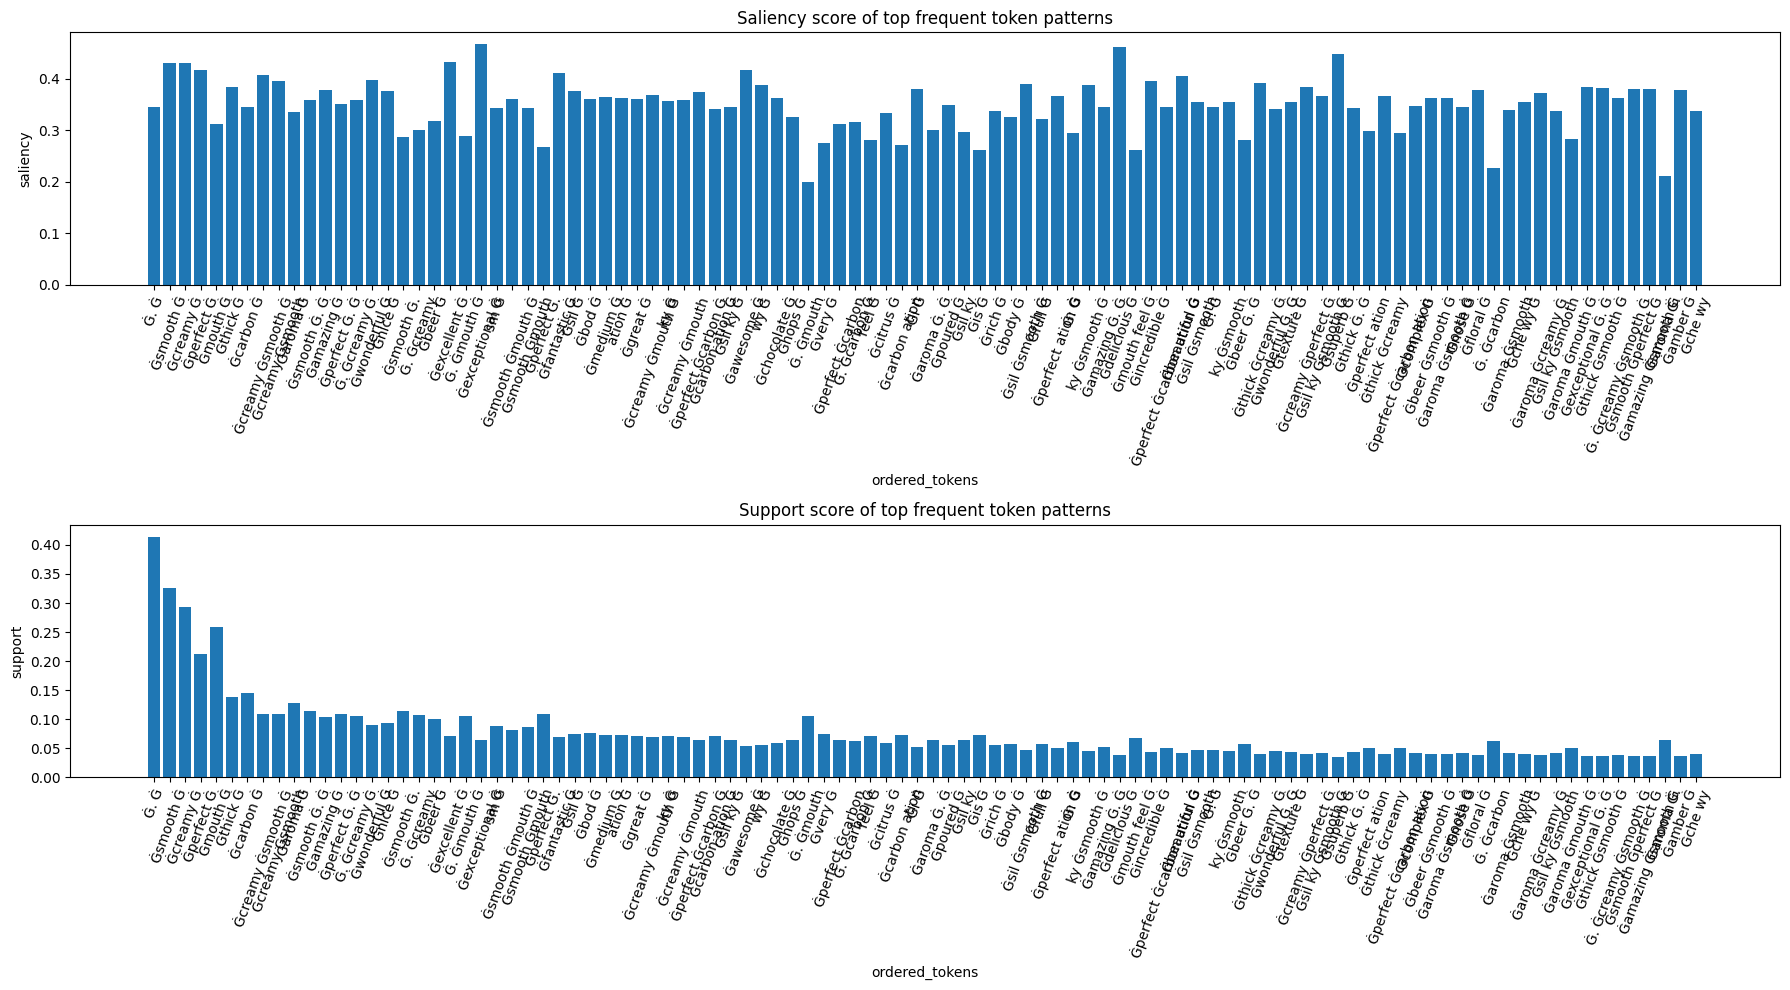

In [18]:
# Convert selected token lists to plot labels.
labels = two_grams["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(18,10))  # Two vertically stacked panels.

# Plot the selected patterns in the first panel.
axes[0].bar(labels, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

# Plot the second pattern metric.
axes[1].bar(labels, two_grams["support"])  # Second panel uses the corresponding pattern data.
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

### Extract GPT-2 token-level hidden states

For `layers=(5, 8, 11, 12)`, `hidden_states[0]` is the embedding output, and `hidden_states[L]` is the output after block L. The slices below contain **only the pattern-token positions**, not the template prefix or padding. GPT-2 uses causal attention, so the last pattern token can attend to the complete preceding pattern sequence.

In [19]:
@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids,
    device,
    layers=(5, 8, 11, 12),
    context_mode="isolated",    # "isolated" or "template"
    template_prefix="This beer is",
    batch_size=STATE_BATCH_SIZE,
    num_labels=4,
    pad_to_length=None,
):
    """Return GPT-2 BPE pattern states per layer and optional classifier logits.

    Unlike BERT, do not add CLS/SEP.  Use prefix + ordered BPE tokens.
    Right-padding is masked, and the exact pattern-token range is recovered.
    Pretrained GPT2Model has no logits; return NaNs in that case.
    """
    model.eval()
    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        raise ValueError("GPT-2 requires a configured pad_token_id")

    if context_mode == "isolated":
        prefix_ids = []
    elif context_mode == "template":
        prefix_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")
    token_start = len(prefix_ids)
    out = {layer: [] for layer in layers}
    logits_out = []

    if not itemsets_token_ids:
        return out, np.empty((0, num_labels), dtype=np.float32)

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]
        input_ids_list = []
        ranges = []
        for pattern in batch_itemsets:
            pattern = [int(i) for i in pattern]
            if not pattern:
                raise ValueError("Cannot extract hidden states for an empty pattern")
            combined = prefix_ids + pattern  # no [CLS], no [SEP]
            if len(combined) > model.config.n_positions:
                raise ValueError("Pattern and prefix exceed GPT-2 context length")
            input_ids_list.append(combined)
            ranges.append((token_start, token_start + len(pattern)))

        length = max(map(len, input_ids_list))
        if pad_to_length is not None:
            if pad_to_length < length:
                raise ValueError("pad_to_length too small")
            length = pad_to_length
        input_ids = torch.tensor(
            [ids + [pad_id] * (length - len(ids)) for ids in input_ids_list],
            dtype=torch.long, device=device,
        )
        attention_mask = torch.tensor(
            [[1] * len(ids) + [0] * (length - len(ids)) for ids in input_ids_list],
            dtype=torch.long, device=device,
        )
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
            return_dict=True,
            use_cache=False,
        )
        if hasattr(outputs, "logits"):
            logits_out.append(outputs.logits.detach().float().cpu().numpy())
        else:
            logits_out.append(np.full((len(input_ids_list), num_labels), np.nan, dtype=np.float32))
        for row_idx, (s, e) in enumerate(ranges):
            for layer in layers:
                out[layer].append(
                    outputs.hidden_states[layer][row_idx, s:e, :]
                    .detach().float().cpu().numpy()
                )

    return out, np.vstack(logits_out)


### Extract pattern representations in isolated and templated contexts

Both models use the same GPT-2 BPE IDs. Isolated: `pattern`. Templated: tokenized `"This beer is"` + `pattern` (no suffix). This is a controlled prefix-token concatenation, **not** a guarantee that the decoded pattern forms a natural grammatical continuation.

In [20]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Extract pretrained representations.
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Extract fine-tuned representations.
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_gpt2, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

### Add Hidden-State Representations to the DataFrame

In [21]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])

### Compare pretrained and fine-tuned pattern representations

**Default: final pattern token**. The corresponding GPT-2 hidden state has attended to all earlier pattern tokens, unlike the first token or the average of causally asymmetric states. Change `PATTERN_POOLING = "mean"` in the configuration cell to reproduce the original Beer mean-pooling view as a sensitivity analysis.

In [22]:
def pool(x):
    """GPT-2 causal pattern representation: last token (or mean sensitivity)."""
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 1:
        return x
    if x.ndim != 2 or x.shape[0] == 0:
        raise ValueError(f"Expected nonempty [pattern_length, hidden_size], got {x.shape}")
    return x[-1] if PATTERN_POOLING == "last" else x.mean(axis=0)


def cos_shift(pt, ft):
    a, b = pool(pt), pool(ft)
    return float(1.0 - np.dot(a, b) / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-12))


def euc_dist(pt, ft):
    return float(np.linalg.norm(pool(pt) - pool(ft)))


layers = (5, 8, 11, 12)
top = two_grams.sort_values("support", ascending=False).head(30).copy()
for L in layers:
    for context in ("iso", "tpl"):
        top[f"cos_shift_{context}_l{L}"] = [
            cos_shift(pt, ft) for pt, ft in zip(top[f"pt_{context}_l{L}"], top[f"ft_{context}_l{L}"])
        ]
        top[f"euc_{context}_l{L}"] = [
            euc_dist(pt, ft) for pt, ft in zip(top[f"pt_{context}_l{L}"], top[f"ft_{context}_l{L}"])
        ]


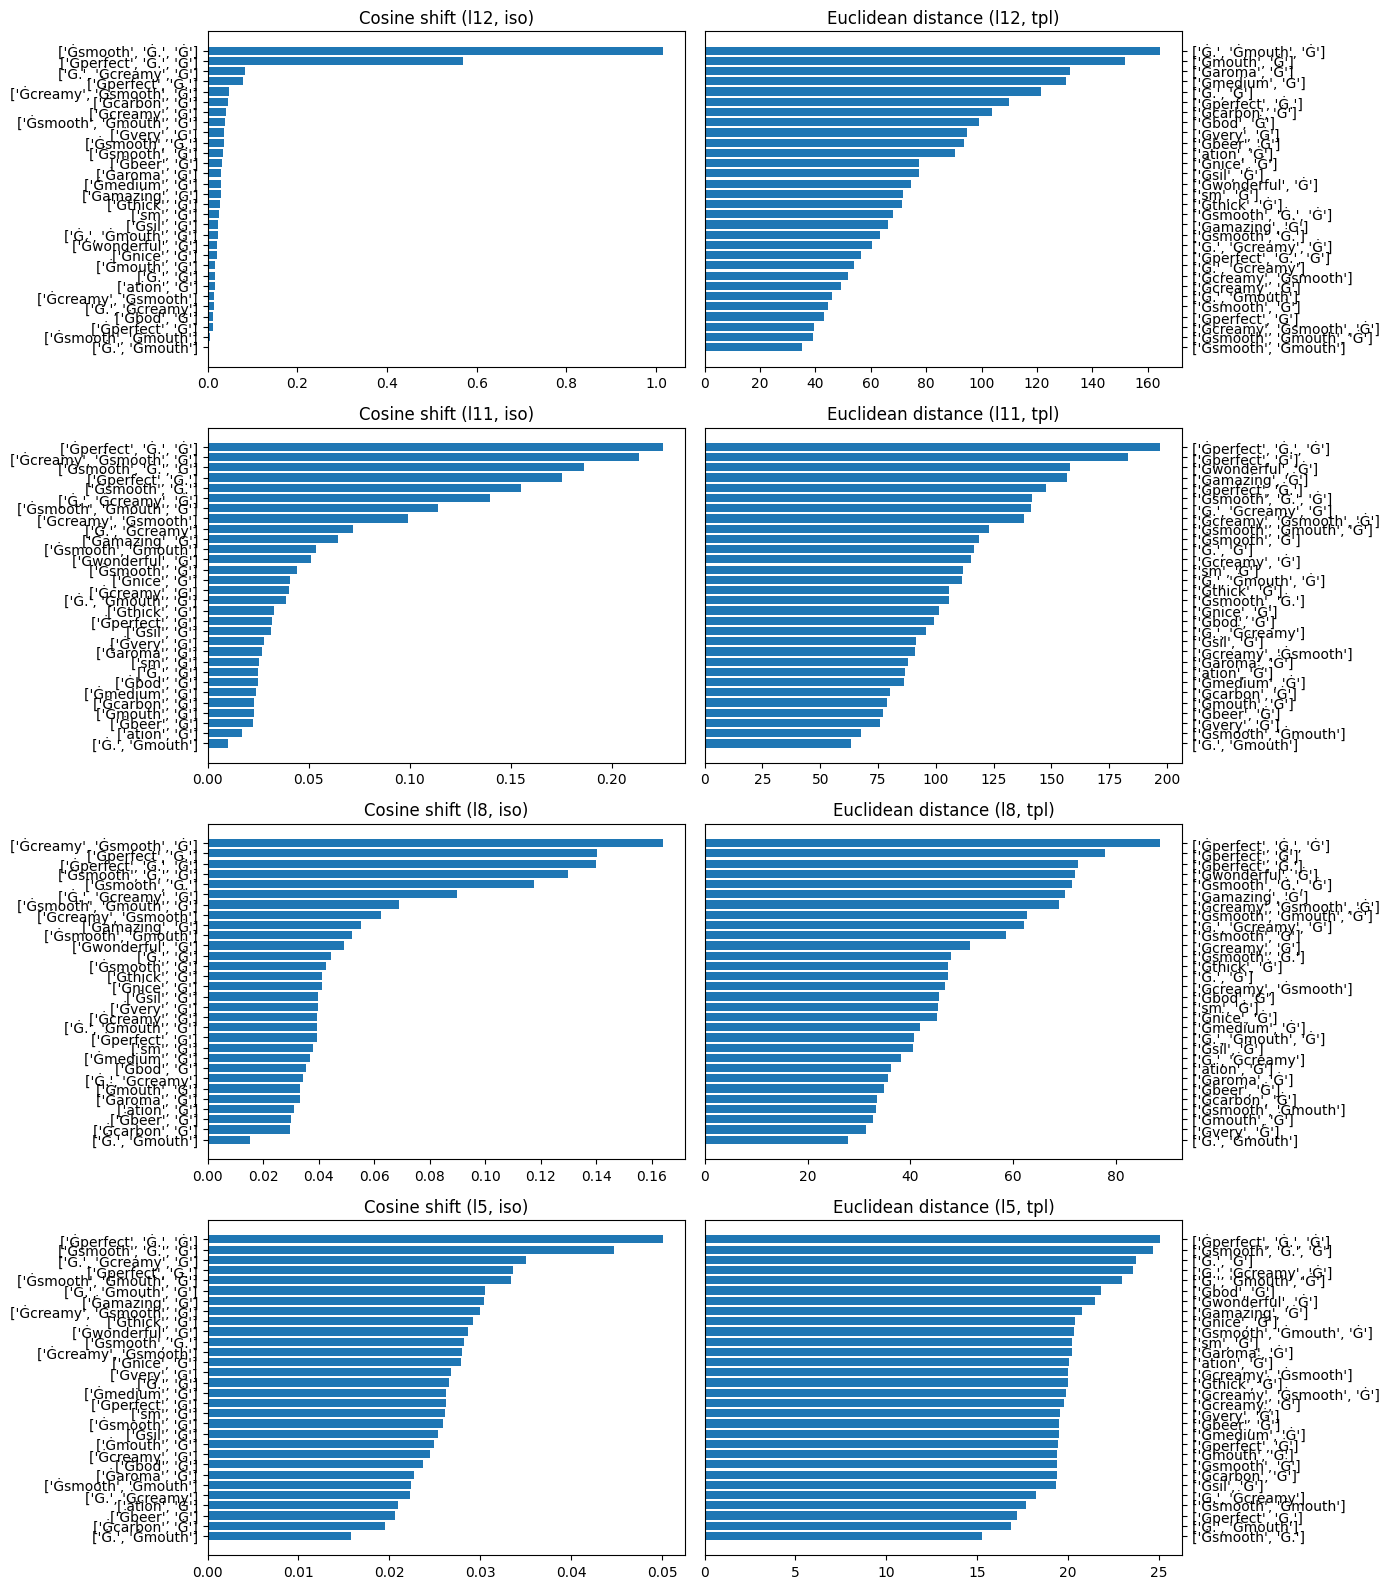

In [23]:
# Visualize representation-distance changes.

layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # Cosine-distance panel.
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # Euclidean-distance panel.
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # Offset right-side labels to reduce overlap.
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()


**Experiment 1 outputs.** Class-specific frequent patterns remain available in `freq_itemsets_by_class[0]` through `[3]` and in the four `freq_itemsets_class*_10` DataFrames. The next section compares neighbours of the mined patterns in pretrained and fine-tuned GPT-2.

## Experiment 2: Direct GPT-2 representation shifts and nearest-neighbour changes

The original Beer analysis is retained with GPT-2 byte-level BPE patterns. Compare **pretrained GPT-2 (PT)** and **fine-tuned correlation1 GPT-2 (FT)** at layers **5, 8, 11, 12** in isolated and templated contexts.

- **Pooling:** `PATTERN_POOLING` (`"last"` by default, `"mean"` for a BERT-like sensitivity analysis). For the default, the last BPE token's causal hidden state represents the ordered pattern.
- **Shared cache:** all class-specific mined patterns and singleton BPE token IDs are deduplicated and processed once per model/context, with fixed right-padding lengths.
- **Direct shift:** `1 − cosine(PT, FT)` and Euclidean distance for the *same* pattern.
- **Neighbour shift:** select closest 10/30 singleton tokens by cosine in **FT** space, exclude constituent IDs, and compare *those exact IDs* in PT and FT spaces.
- **Interpretation:** a geometric shift does not, by itself, demonstrate causal shortcut usage. These mined token patterns may be noncontiguous in the original reviews.

In [ ]:
# Layers, contexts, FT-neighbour counts for both GPT-2 models.
NN_LAYERS = (5, 8, 11, 12)
NN_CONTEXTS = {"iso": "isolated", "tpl": "template"}
NN_K_VALUES = (10, 30)
NN_TEMPLATE_PREFIX = "This beer is"
NN_BATCH_SIZE = STATE_BATCH_SIZE


def nn_extract_pattern_states(model, pattern_ids, context, batch_size=NN_BATCH_SIZE):
    """Cache the selected GPT-2 pattern representation with fixed right padding."""
    if not pattern_ids:
        raise ValueError("Cannot extract representations for an empty pattern list")
    hs, _ = extract_itemset_hidden_states(
        model=model,
        tokenizer=tokenizer,
        itemsets_token_ids=pattern_ids,
        device=device,
        layers=NN_LAYERS,
        context_mode=NN_CONTEXTS[context],
        template_prefix=NN_TEMPLATE_PREFIX,
        batch_size=batch_size,
        pad_to_length=NN_FIXED_PAD_LENGTH[context],
    )
    return {
        L: np.stack([pool(x) for x in hs[L]]).astype(np.float32)
        for L in NN_LAYERS
    }


def nn_normalize_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    return matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12)


### Shared GPT-2 representation cache and neighbour vocabulary

Candidates are **GPT-2 BPE tokens** appearing in frequent patterns. Single-token candidates and longer patterns share the exact same extraction and pooling logic. GPT-2 uses no special tokens around patterns, so the fixed padded lengths contain just the pattern or template prefix + pattern.

In [25]:
# Build the shared candidate-token pool across all predicted classes.
NN_TOKEN_IDS = sorted({
    int(token_id)
    for c in range(4)
    for ids in freq_itemsets_by_class[c]["ordered_ids"]
    for token_id in ids
})
if len(NN_TOKEN_IDS) < 2:
    raise ValueError("Need at least two mined token IDs to compute neighbours")
if len(NN_TOKEN_IDS) < max(NN_K_VALUES) + 4:
    print(f"Note: only {len(NN_TOKEN_IDS)} candidate tokens; some patterns may have fewer than 30 eligible neighbours.")

NN_TOKEN_LABELS = tokenizer.convert_ids_to_tokens(NN_TOKEN_IDS)
NN_TOKEN_IDS_ARRAY = np.asarray(NN_TOKEN_IDS, dtype=int)

# Each ordered token-ID sequence is encoded once, regardless of the number of classes containing it.
NN_PATTERN_KEYS = sorted({
    tuple(map(int, ids))
    for c in range(4)
    for ids in freq_itemsets_by_class[c]["ordered_ids"]
}.union({(tid,) for tid in NN_TOKEN_IDS}), key=lambda key: (len(key), key))
NN_PATTERN_INDEX = {key: i for i, key in enumerate(NN_PATTERN_KEYS)}
NN_TOKEN_INDICES = np.asarray([NN_PATTERN_INDEX[(tid,)] for tid in NN_TOKEN_IDS], dtype=int)
NN_PATTERN_LIST = [list(key) for key in NN_PATTERN_KEYS]

# A single padding length per context avoids dependence on other patterns in an extraction batch.
_max_pattern_len = max(map(len, NN_PATTERN_KEYS))
NN_FIXED_PAD_LENGTH = {
    "iso": _max_pattern_len,  # GPT-2: pattern only
    "tpl": len(tokenizer(NN_TEMPLATE_PREFIX, add_special_tokens=False).input_ids) + _max_pattern_len,
}

# Shared [n_unique_patterns, hidden_size] matrices for each model, context, and layer.
nn_pattern_vectors = {}
for context in NN_CONTEXTS:
    for model_type, model in (("pt", pt_gpt2), ("ft", ft_gpt2)):
        print(f"Encoding {len(NN_PATTERN_KEYS)} unique patterns: {model_type}, {context}")
        states = nn_extract_pattern_states(model, NN_PATTERN_LIST, context)
        for L in NN_LAYERS:
            nn_pattern_vectors[(model_type, context, L)] = states[L]

# Check consistency of a small fixed sample across extraction batch sizes.
_check_keys = [(tid,) for tid in NN_TOKEN_IDS[:min(3, len(NN_TOKEN_IDS))]]
for context in NN_CONTEXTS:
    for model_type, model in (("pt", pt_gpt2), ("ft", ft_gpt2)):
        single = nn_extract_pattern_states(model, [list(k) for k in _check_keys], context, batch_size=1)
        for L in NN_LAYERS:
            reference = nn_pattern_vectors[(model_type, context, L)][
                [NN_PATTERN_INDEX[k] for k in _check_keys]
            ]
            max_difference = float(np.max(np.abs(reference - single[L])))
            if not np.allclose(
                reference,
                single[L],
                rtol=1e-3,
                atol=3e-3,
            ):
                raise RuntimeError(
                    f"Inconsistent hidden states across batch sizes "
                    f"for {model_type}/{context}/L{L}: "
                    f"max absolute difference = {max_difference:.5g}"
                )

# Reuse the same candidate vectors as the pattern vectors for single-token patterns.
NN_GEOMETRY = {}
for context in NN_CONTEXTS:
    for L in NN_LAYERS:
        pt_all = nn_pattern_vectors[("pt", context, L)]
        ft_all = nn_pattern_vectors[("ft", context, L)]
        pt_norm = nn_normalize_rows(pt_all)
        ft_norm = nn_normalize_rows(ft_all)
        ft_candidate_norm = ft_norm[NN_TOKEN_INDICES]
        NN_GEOMETRY[(context, L)] = {
            "pt_all": pt_all,
            "ft_all": ft_all,
            "pt_norm": pt_norm,
            "ft_norm": ft_norm,
            "pt_candidates": pt_all[NN_TOKEN_INDICES],
            "ft_candidates": ft_all[NN_TOKEN_INDICES],
            "pt_candidate_norm": pt_norm[NN_TOKEN_INDICES],
            "ft_candidate_norm": ft_candidate_norm,
            "ft_similarities": ft_norm @ ft_candidate_norm.T,
            "direct_cosine": np.maximum(0.0, 1.0 - np.sum(pt_norm * ft_norm, axis=1)),
            "direct_euclidean": np.linalg.norm(pt_all - ft_all, axis=1),
        }

print("Shared neighbour vocabulary size:", len(NN_TOKEN_IDS))
print("Unique pattern sequences:", len(NN_PATTERN_KEYS))
print("Batch-size representation consistency: passed")


Encoding 2666 unique patterns: pt, iso
Encoding 2666 unique patterns: ft, iso
Encoding 2666 unique patterns: pt, tpl
Encoding 2666 unique patterns: ft, tpl
Shared neighbour vocabulary size: 286
Unique pattern sequences: 2666
Batch-size representation consistency: passed


### Direct Pattern Shift and Fine-Tuned Neighbour Comparison

Each pattern's own PT–FT cosine and Euclidean distances are computed directly from its cached vectors. The same pattern is then compared to the NN-10 and NN-30 tokens selected in FT space. PT distances are measured to those exact neighbour IDs. Repeated token-ID sequences across predicted classes share identical vectors, neighbour identities, and distance metrics.


In [28]:
def nn_class_distance_comparison(predicted_class):
    """Measure direct pattern shifts and FT-neighbour distance changes for one class."""
    source = freq_itemsets_by_class[predicted_class].reset_index(drop=True)
    if source.empty:
        return pd.DataFrame()

    pattern_keys = [tuple(map(int, ids)) for ids in source["ordered_ids"]]
    rows = []

    for context in NN_CONTEXTS:
        for L in NN_LAYERS:
            geom = NN_GEOMETRY[(context, L)]
            for i, key in enumerate(pattern_keys):
                pattern_idx = NN_PATTERN_INDEX[key]
                # similarities = geom["ft_similarities"][pattern_idx].copy()
                # # Exclude the anchor's constituent GPT-2 BPE IDs.
                # similarities[np.isin(NN_TOKEN_IDS_ARRAY, key)] = -np.inf
                # n_select = min(max(NN_K_VALUES), int(np.isfinite(similarities).sum()))
                # if not n_select:
                #     continue
                # candidate_indices = np.argsort(similarities)[-n_select:][::-1]
                # Select nearest tokens using Euclidean distance in FT space.
                ##########################################################################################
                # distances = np.linalg.norm(
                #     geom["ft_candidates"] - geom["ft_all"][pattern_idx],
                #     axis=1
                # )
                distances = 1 - geom["ft_similarities"][pattern_idx].copy()
                # Exclude tokens belonging to the pattern.
                distances[np.isin(NN_TOKEN_IDS_ARRAY, key)] = np.inf

                n_select = min(max(NN_K_VALUES), int(np.isfinite(distances).sum()))
                if not n_select:
                    continue

                candidate_indices = np.argsort(distances)[:n_select]


                ft_query = geom["ft_all"][pattern_idx]
                pt_query = geom["pt_all"][pattern_idx]
                ft_query_norm = geom["ft_norm"][pattern_idx]
                pt_query_norm = geom["pt_norm"][pattern_idx]

                ft_cos_dist = np.maximum(
                    0.0, 1.0 - geom["ft_candidate_norm"][candidate_indices] @ ft_query_norm
                )
                pt_cos_dist = np.maximum(
                    0.0, 1.0 - geom["pt_candidate_norm"][candidate_indices] @ pt_query_norm
                )
                ft_euc_dist = np.linalg.norm(
                    geom["ft_candidates"][candidate_indices] - ft_query, axis=1
                )
                pt_euc_dist = np.linalg.norm(
                    geom["pt_candidates"][candidate_indices] - pt_query, axis=1
                )

                for k in NN_K_VALUES:
                    n = min(k, n_select)
                    cos_ft, cos_pt = ft_cos_dist[:n], pt_cos_dist[:n]
                    euc_ft, euc_pt = ft_euc_dist[:n], pt_euc_dist[:n]
                    cos_signed = cos_pt - cos_ft
                    euc_signed = euc_pt - euc_ft

                    rows.append({
                        "predicted_class": predicted_class,
                        "rating": ID_TO_RATING[predicted_class],
                        "pattern_text": " ".join(source.iloc[i]["ordered_tokens"]),
                        "ordered_tokens": list(source.iloc[i]["ordered_tokens"]),
                        "ordered_ids": list(key),
                        "length": int(source.iloc[i]["length"]),
                        "support": float(source.iloc[i]["support"]),
                        "support_count": int(source.iloc[i]["support_count"]),
                        "saliency_score": float(source.iloc[i]["saliency_score"]),
                        "score": float(source.iloc[i]["score"]),
                        "layer": L,
                        "context": context,
                        "k": k,
                        "actual_k": n,
                        "direct_cosine_shift": float(geom["direct_cosine"][pattern_idx]),
                        "direct_euclidean_shift": float(geom["direct_euclidean"][pattern_idx]),
                        "ft_nn_token_ids": NN_TOKEN_IDS_ARRAY[candidate_indices[:n]].tolist(),
                        "ft_nn_tokens": [NN_TOKEN_LABELS[j] for j in candidate_indices[:n]],
                        "ft_nn_cosine_distances": cos_ft.tolist(),
                        "pt_same_nn_cosine_distances": cos_pt.tolist(),
                        "signed_cosine_contractions": cos_signed.tolist(),
                        "absolute_cosine_shifts": np.abs(cos_signed).tolist(),
                        "mean_abs_cosine_shift": float(np.abs(cos_signed).mean()),
                        "mean_signed_cosine_contraction": float(cos_signed.mean()),
                        "ft_nn_euclidean_distances": euc_ft.tolist(),
                        "pt_same_nn_euclidean_distances": euc_pt.tolist(),
                        "signed_euclidean_contractions": euc_signed.tolist(),
                        "absolute_euclidean_shifts": np.abs(euc_signed).tolist(),
                        "mean_abs_euclidean_shift": float(np.abs(euc_signed).mean()),
                        "mean_signed_euclidean_contraction": float(euc_signed.mean()),
                    })

    return pd.DataFrame(rows)


In [29]:
# Compute the FT-selected-neighbour comparison for each predicted class.
_nn_class_results = []
for c in range(4):
    print(f"Computing neighbour comparisons for class {c} (palate {ID_TO_RATING[c]:.1f})")
    _nn_class_results.append(nn_class_distance_comparison(c))

nn_shift_df = pd.concat(_nn_class_results, ignore_index=True)
if nn_shift_df.empty:
    raise ValueError("No neighbour comparisons were produced")

# Identical ordered GPT-2 BPE sequences must have identical geometric results across classes.
_check_df = nn_shift_df.copy()
_check_df["_pattern_key"] = _check_df["ordered_ids"].map(tuple)
_geom_columns = [
    "direct_cosine_shift", "direct_euclidean_shift",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
]
_repeated_groups = 0
for _, group in _check_df.groupby(["_pattern_key", "context", "layer", "k"]):
    if len(group) < 2:
        continue
    _repeated_groups += 1
    if len({tuple(ids) for ids in group["ft_nn_token_ids"]}) != 1:
        raise AssertionError("Different FT neighbour IDs for the same pattern, layer, and context")
    values = group[_geom_columns].to_numpy(dtype=float)
    if not np.allclose(values, values[0], rtol=1e-6, atol=1e-6):
        raise AssertionError("Different shift metrics for the same pattern, layer, and context")
print(f"Cross-class neighbour consistency: passed ({_repeated_groups} repeated-pattern groups checked)")

nn_10_df = nn_shift_df.loc[nn_shift_df["k"] == 10].copy()
nn_30_df = nn_shift_df.loc[nn_shift_df["k"] == 30].copy()

# Direct shifts contain no NN-k dependence.
direct_shift_df = nn_10_df.drop(columns=[
    "k", "actual_k", "ft_nn_token_ids", "ft_nn_tokens", "ft_nn_cosine_distances",
    "pt_same_nn_cosine_distances", "signed_cosine_contractions", "absolute_cosine_shifts",
    "mean_abs_cosine_shift", "mean_signed_cosine_contraction", "ft_nn_euclidean_distances",
    "pt_same_nn_euclidean_distances", "signed_euclidean_contractions",
    "absolute_euclidean_shifts", "mean_abs_euclidean_shift",
    "mean_signed_euclidean_contraction",
]).copy()

nn_class0_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 0].copy()
nn_class1_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 1].copy()
nn_class2_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 2].copy()
nn_class3_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 3].copy()

nn_class0_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 0].copy()
nn_class1_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 1].copy()
nn_class2_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 2].copy()
nn_class3_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 3].copy()

print("Result counts by predicted class, context, layer, and neighbour count:")
print(nn_shift_df.groupby(["predicted_class", "context", "layer", "k"]).size().to_string())


Computing neighbour comparisons for class 0 (palate 0.4)
Computing neighbour comparisons for class 1 (palate 0.6)
Computing neighbour comparisons for class 2 (palate 0.8)
Computing neighbour comparisons for class 3 (palate 1.0)
Cross-class neighbour consistency: passed (12080 repeated-pattern groups checked)
Result counts by predicted class, context, layer, and neighbour count:
predicted_class  context  layer  k 
0                iso      5      10     648
                                 30     648
                          8      10     648
                                 30     648
                          11     10     648
                                 30     648
                          12     10     648
                                 30     648
                 tpl      5      10     648
                                 30     648
                          8      10     648
                                 30     648
                          11     10     648
           

### Nearest-Neighbour and Direct-Shift Results

`nn_10_df` and `nn_30_df` contain the FT-neighbour comparison for 10 and 30 neighbours, respectively, for each predicted class, context, and layer. Both now also include **`direct_cosine_shift`** and **`direct_euclidean_shift`**, which compare the pattern's own PT and FT representations without involving neighbours.

`direct_shift_df` contains one row per class, pattern, context, and layer, without the duplicate NN-10/NN-30 measurements. The four `nn_class*_10_df` and four `nn_class*_30_df` DataFrames remain available for class-specific inspection.

- **Direct shift:** `direct_cosine_shift`, `direct_euclidean_shift`.
- **FT-selected neighbour shift:** `mean_abs_cosine_shift`, `mean_abs_euclidean_shift`.
- **Signed neighbour contraction:** `mean_signed_cosine_contraction`, `mean_signed_euclidean_contraction` (positive = neighbours closer in FT).

When comparing patterns across predicted classes, use the same layer and context. Equal ordered BPE token-ID sequences produce identical geometric measurements, although their class-specific support and saliency can differ.


In [30]:
# Example: top 30 shifted patterns for predicted class 3 at layer 12 (templated, NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl'").sort_values(
    "mean_abs_cosine_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
60631,Ġ`` Ġ,2,0.021073,0.341534,0.007197,1.087525,29.037205,-1.087525,-28.876101,"[Ġfull, Ġdense, Ġvisc, Ġthick, bodied, full, Ġ...",30
60391,Ġ. Ġi Ġ,3,0.021073,0.337146,0.007105,1.083850,132.227005,-1.083850,-132.227005,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġsk, Ġche,...",30
60103,Ġ. Ġ: Ġ,3,0.019157,0.275080,0.005270,1.037918,80.682373,-1.037918,-80.682373,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,...",30
61181,Ġarom Ġ. Ġ,3,0.015326,0.314570,0.004821,0.792803,87.138260,-0.792803,-87.138260,"[Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt, Ġgras...",30
59915,Ġ. Ġ,2,0.413793,0.344699,0.142634,0.778289,83.746895,-0.778289,-83.746895,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġsk, Ġvel, Ġho, ...",30
60597,Ġis Ġ. Ġ,3,0.022989,0.268124,0.006164,0.778056,84.040436,-0.778056,-84.040436,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġho, Ġsk, ...",30
61633,Ġtan Ġ. Ġ,3,0.011494,0.313719,0.003606,0.713509,96.090286,-0.713509,-96.090286,"[Ġarom, Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt...",30
60741,Ġstout Ġ. Ġ,3,0.013410,0.355576,0.004768,0.612339,92.282387,-0.612339,-92.282387,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġmalt, Ġfru...",30
61725,Ġ- Ġ. Ġ,3,0.015326,0.279123,0.004278,0.556193,56.375420,-0.556193,-56.375420,"[Ġarom, Ġip, Ġdec, Ġha, Ġche, Ġsk, Ġfru, Ġvel,...",30
60469,Ġ. Ġmouth Ġ,3,0.105364,0.289779,0.030532,0.543649,109.741440,-0.543649,-109.741440,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,...",30


In [31]:
# Example: top 30 shifted single-token patterns for class 0 at layer 5 (isolated, NN-10).
nn_class0_10_df.query("layer == 5 and context == 'iso' and length == 1").sort_values(
    "mean_abs_euclidean_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
0,Ġ,1,0.971989,0.460341,0.447447,0.000016,5.465185,-0.000016,-5.465185,"[Ġip, Ġha, Ġi, Ġ``, Ġ!, Ġsy, izz, Ġfo, Ġbod, Ġ...",10
154,Ġunpleasant,1,0.019608,0.320295,0.006280,0.000006,3.927174,-0.000006,-3.927174,"[Ġpleasant, Ġbad, Ġbitter, Ġenjoyable, Ġpleasi...",10
206,Ġflat,1,0.047619,0.267842,0.012754,0.000006,3.654221,-0.000006,-3.654221,"[Ġthin, Ġthick, Ġdry, Ġdark, Ġcrisp, Ġsolid, Ġ...",10
82,Ġcaramel,1,0.016807,0.190200,0.003197,0.000008,3.591504,-0.000008,-3.591504,"[Ġvanilla, Ġchocolate, Ġamber, Ġcreamy, Ġroast...",10
42,amy,1,0.050420,0.327321,0.016504,0.000004,3.480744,-0.000004,-3.480744,"[iness, ours, thy, zy, alty, y, ky, ty, asty, ...",10
114,Ġ!,1,0.030812,0.216419,0.006668,0.000006,3.380704,-0.000006,-3.198713,"[Ġ., Ġ:, Ġ..., Ġ;, Ġ-, Ġ,, Ġi, s, Ġok, Ġ']",10
136,Ġpretty,1,0.039216,0.231184,0.009066,0.000008,3.252010,-0.000008,-3.252010,"[Ġquite, Ġvery, Ġsomewhat, Ġincredibly, Ġreall...",10
202,Ġbub,1,0.016807,0.217120,0.003649,0.000010,3.181224,-0.000010,-3.181224,"[izz, Ġdecad, Ġhop, Ġche, Ġbland, Ġbrew, Ġsk, ...",10
2,Ġmouth,1,0.316527,0.227421,0.071985,0.000005,3.176261,-0.000005,-3.176261,"[Ġtongue, Ġnose, Ġpalate, Ġbody, Ġdrink, Ġfing...",10
214,Ġbland,1,0.022409,0.312356,0.007000,0.000007,3.102177,-0.000007,-2.951952,"[Ġpleasant, Ġdecent, Ġbitter, Ġweak, Ġbrown, Ġ...",10


In [32]:
# Example: class 3 multi-token patterns ranked by signed cosine contraction (NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl' and length > 1").sort_values(
    "mean_signed_cosine_contraction", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_signed_cosine_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_signed_cosine_contraction,ft_nn_tokens,actual_k
61723,Ġ- Ġ.,2,0.015326,0.171985,0.002636,0.011086,0.011086,"[Ġ:, very, feel, y, Ġ,, Ġshines, Ġlooks, Ġ;, w...",30
60675,Ġ! Ġsmooth Ġ,3,0.011494,0.366281,0.004210,0.009831,0.009017,"[cious, ty, Ġfeels, Ġstrong, Ġlovely, Ġ..., Ġl...",30
60581,Ġis Ġ.,2,0.022989,0.177920,0.004090,0.008542,0.008542,"[Ġ:, Ġ-, very, feel, y, Ġlooks, Ġ,, Ġshines, Ġ...",30
61021,Ġperfect Ġcarbon ation,3,0.049808,0.295058,0.014696,0.008002,0.008002,"[Ġfantastic, Ġgorgeous, Ġgreat, Ġsuperb, Ġwond...",30
61563,Ġcitrus Ġperfect Ġ,3,0.015326,0.340736,0.005222,0.006961,0.006430,"[cious, Ġrich, Ġcreamy, Ġdense, Ġsublime, Ġ!, ...",30
60585,Ġthick Ġis,2,0.011494,0.221708,0.002548,0.008835,0.005673,"[Ġbeautifully, Ġtoo, Ġwonderfully, Ġfeels, Ġhi...",30
61535,Ġmouth ky Ġsmooth Ġ,4,0.013410,0.340736,0.004569,0.005542,0.005422,"[cious, sweet, ty, Ġsuper, Ġcreamy, Ġfluffy, Ġ...",30
60459,Ġ. Ġcreamy Ġsmooth Ġ,4,0.038314,0.362262,0.013880,0.007798,0.005243,"[Ġsuper, cious, ty, Ġspicy, a, Ġbeautifully, Ġ...",30
61159,Ġhops Ġperfect Ġ,3,0.019157,0.345197,0.006613,0.006301,0.005219,"[Ġdense, Ġrich, Ġdelicious, Ġbeautiful, cious,...",30
60241,Ġaroma Ġperfect Ġ,3,0.021073,0.368685,0.007769,0.005120,0.004877,"[cious, Ġ!, Ġdelicious, Ġrich, Ġdense, Ġbeauti...",30


### Inspect Direct Shifts by Predicted Class

The direct shift rankings do not depend on the number of neighbours. Filter `direct_shift_df` by predicted class, layer, and context to identify the most changed token or token-group representations. The FP-Growith support and saliency columns are preserved for comparison.


In [33]:
# Highest direct cosine shifts for predicted class 3, layer 11, templated input.
direct_shift_df.query("predicted_class == 3 and layer == 11 and context == 'tpl'").sort_values(
    "direct_cosine_shift", ascending=False
)[["pattern_text", "length", "support", "saliency_score", "score", "direct_cosine_shift", "direct_euclidean_shift"]].head(30)


,pattern_text,length,support,saliency_score,score,direct_cosine_shift,direct_euclidean_shift
57754,Ġcreamy Ġperfect Ġ. Ġ,4,0.021073,0.346969,0.007312,0.390613,205.983246
57748,Ġperfect Ġ. Ġ,3,0.109195,0.351121,0.038341,0.373127,196.825027
58350,Ġbeer Ġperfect Ġ. Ġ,4,0.017241,0.294004,0.005069,0.370011,196.776688
57762,Ġperfect Ġ. Ġmouth Ġ,4,0.019157,0.323966,0.006206,0.357029,189.745911
58760,Ġperfect wy Ġ,3,0.011494,0.364331,0.004188,0.352990,201.669128
58498,Ġperfect Ġ! Ġ,3,0.013410,0.389921,0.005229,0.351817,194.355713
58830,Ġperfect ation Ġ. Ġ,4,0.022989,0.343693,0.007901,0.340661,188.476379
58620,Ġamazing Ġcreamy Ġ. Ġ,4,0.013410,0.336879,0.004518,0.340429,187.908798
58066,Ġaroma Ġperfect Ġ. Ġ,4,0.015326,0.332909,0.005102,0.336697,191.632050
58872,Ġwonderful Ġcreamy Ġ. Ġ,4,0.011494,0.359948,0.004137,0.336685,186.859650


**Experiment 2 outputs.** `nn_10_df` and `nn_30_df` contain all nearest-neighbour comparisons. Class-specific results are available in `nn_class0_10_df` through `nn_class3_10_df` and `nn_class0_30_df` through `nn_class3_30_df`. The tables retain the fine-tuned neighbour IDs, their token labels, and distances for those same neighbour pairs in pretrained and fine-tuned GPT-2.

In [34]:
# nn_10_df.to_csv("nn_10_results_correlation.csv", index=False)
# nn_30_df.to_csv("nn_30_results_correlation.csv", index=False)

In [35]:

# Top 30 most strongly shifted patterns at layer 12
# Repeat for classes 0/3 and NN-10/NN-30.

top30_neighborhood_shifts = {}

for class_id in (0, 3):
    for k in (10, 30):
        result = (
            nn_shift_df
            .query(
                "predicted_class == @class_id "
                "and layer == 12 "
                "and k == @k "
                "and context == 'tpl'"
            )
            .sort_values("mean_abs_cosine_shift", ascending=False)
            [[
                "pattern_text",
                "length",
                "support",
                "saliency_score",
                "score",
                "mean_abs_cosine_shift",
                "mean_abs_euclidean_shift",
                "mean_signed_cosine_contraction",
                "ft_nn_tokens",
            ]]
            .head(30)
            .reset_index(drop=True)
        )

        top30_neighborhood_shifts[(class_id, k)] = result

        print(f"Palate {ID_TO_RATING[class_id]:.1f} | NN-{k}")
        display(result)


Palate 0.4 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġ- Ġ,3,0.030812,0.278603,0.008584,1.379039,93.326149,-1.379039,"[Ġarom, Ġsil, Ġche, Ġvel, Ġdissip, Ġsy, Ġvisc,..."
1,Ġthin Ġmedium Ġ. Ġ,4,0.016807,0.347668,0.005843,1.124830,103.457436,-1.124830,"[Ġip, Ġarom, Ġvisc, Ġcarbon, Ġfru, Ġha, Ġbub, ..."
2,Ġ. Ġ,2,0.445378,0.355970,0.158541,0.737776,82.068405,-0.737776,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġsk, Ġvel, Ġho, ..."
3,Ġ: Ġ. Ġ,3,0.036415,0.327320,0.011919,0.713786,83.006500,-0.713786,"[Ġarom, Ġip, Ġha, Ġdec, Ġho, Ġvel, Ġfru, Ġmalt..."
4,Ġ. ours Ġ,3,0.030812,0.323387,0.009964,0.611877,101.076271,-0.611877,"[Ġarom, Ġip, Ġha, Ġvel, Ġfru, Ġsk, Ġdec, Ġho, ..."
5,Ġfaint Ġ. Ġ,3,0.036415,0.326261,0.011881,0.523425,96.347755,-0.523425,"[Ġip, Ġarom, Ġcarbon, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."
6,Ġ. Ġmouth Ġ,3,0.142857,0.321409,0.045916,0.502131,106.884644,-0.502131,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
7,Ġ. Ġm Ġ,3,0.019608,0.310949,0.006097,0.493719,114.434708,-0.493719,"[Ġarom, Ġip, Ġha, Ġvel, Ġdec, Ġho, Ġfru, Ġsk, ..."
8,Ġ. Ġis Ġ,3,0.016807,0.289907,0.004872,0.479831,101.487862,-0.479831,"[Ġarom, Ġvel, Ġfru, Ġha, Ġsk, Ġip, Ġho, Ġbub, ..."
9,Ġmalt Ġ. Ġ,3,0.016807,0.308539,0.005186,0.439248,74.191116,-0.439248,"[Ġip, Ġarom, Ġha, Ġho, Ġdec, Ġfru, Ġcocoa, Ġca..."


Palate 0.4 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġ- Ġ,3,0.030812,0.278603,0.008584,1.413130,85.566238,-1.413130,"[Ġarom, Ġsil, Ġche, Ġvel, Ġdissip, Ġsy, Ġvisc,..."
1,Ġthin Ġmedium Ġ. Ġ,4,0.016807,0.347668,0.005843,1.163841,108.393707,-1.163841,"[Ġip, Ġarom, Ġvisc, Ġcarbon, Ġfru, Ġha, Ġbub, ..."
2,Ġ. Ġ,2,0.445378,0.355970,0.158541,0.778289,83.746895,-0.778289,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġsk, Ġvel, Ġho, ..."
3,Ġ: Ġ. Ġ,3,0.036415,0.327320,0.011919,0.758583,85.315598,-0.758583,"[Ġarom, Ġip, Ġha, Ġdec, Ġho, Ġvel, Ġfru, Ġmalt..."
4,Ġ. ours Ġ,3,0.030812,0.323387,0.009964,0.666610,108.494156,-0.666610,"[Ġarom, Ġip, Ġha, Ġvel, Ġfru, Ġsk, Ġdec, Ġho, ..."
5,Ġfaint Ġ. Ġ,3,0.036415,0.326261,0.011881,0.555913,107.569450,-0.555913,"[Ġip, Ġarom, Ġcarbon, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."
6,Ġ. Ġmouth Ġ,3,0.142857,0.321409,0.045916,0.543649,109.741440,-0.543649,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
7,Ġ. Ġm Ġ,3,0.019608,0.310949,0.006097,0.531603,109.984520,-0.531603,"[Ġarom, Ġip, Ġha, Ġvel, Ġdec, Ġho, Ġfru, Ġsk, ..."
8,Ġ. Ġis Ġ,3,0.016807,0.289907,0.004872,0.507250,107.389252,-0.507250,"[Ġarom, Ġvel, Ġfru, Ġha, Ġsk, Ġip, Ġho, Ġbub, ..."
9,Ġmalt Ġ. Ġ,3,0.016807,0.308539,0.005186,0.483647,77.863518,-0.483647,"[Ġip, Ġarom, Ġha, Ġho, Ġdec, Ġfru, Ġcocoa, Ġca..."


Palate 1.0 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ`` Ġ,2,0.021073,0.341534,0.007197,1.076645,33.542549,-1.076645,"[Ġfull, Ġdense, Ġvisc, Ġthick, bodied, full, Ġ..."
1,Ġ. Ġi Ġ,3,0.021073,0.337146,0.007105,1.031510,136.721313,-1.031510,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġsk, Ġche,..."
2,Ġ. Ġ: Ġ,3,0.019157,0.275080,0.005270,0.988809,79.319336,-0.988809,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
3,Ġarom Ġ. Ġ,3,0.015326,0.314570,0.004821,0.751585,85.093521,-0.751585,"[Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt, Ġgras..."
4,Ġ. Ġ,2,0.413793,0.344699,0.142634,0.737776,82.068405,-0.737776,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġsk, Ġvel, Ġho, ..."
5,Ġis Ġ. Ġ,3,0.022989,0.268124,0.006164,0.736803,80.749901,-0.736803,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġho, Ġsk, ..."
6,Ġtan Ġ. Ġ,3,0.011494,0.313719,0.003606,0.660585,94.048744,-0.660585,"[Ġarom, Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt..."
7,Ġstout Ġ. Ġ,3,0.013410,0.355576,0.004768,0.567072,88.811050,-0.567072,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġmalt, Ġfru..."
8,Ġ- Ġ. Ġ,3,0.015326,0.279123,0.004278,0.523366,53.873730,-0.523366,"[Ġarom, Ġip, Ġdec, Ġha, Ġche, Ġsk, Ġfru, Ġvel,..."
9,Ġbeautiful Ġ. Ġ,3,0.017241,0.354462,0.006111,0.510727,74.037796,-0.510727,"[full, Ġdense, Ġrich, Ġdelicious, Ġcomplex, Ġ`..."


Palate 1.0 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ`` Ġ,2,0.021073,0.341534,0.007197,1.087525,29.037205,-1.087525,"[Ġfull, Ġdense, Ġvisc, Ġthick, bodied, full, Ġ..."
1,Ġ. Ġi Ġ,3,0.021073,0.337146,0.007105,1.083850,132.227005,-1.083850,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġsk, Ġche,..."
2,Ġ. Ġ: Ġ,3,0.019157,0.275080,0.005270,1.037918,80.682373,-1.037918,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
3,Ġarom Ġ. Ġ,3,0.015326,0.314570,0.004821,0.792803,87.138260,-0.792803,"[Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt, Ġgras..."
4,Ġ. Ġ,2,0.413793,0.344699,0.142634,0.778289,83.746895,-0.778289,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġsk, Ġvel, Ġho, ..."
5,Ġis Ġ. Ġ,3,0.022989,0.268124,0.006164,0.778056,84.040436,-0.778056,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġho, Ġsk, ..."
6,Ġtan Ġ. Ġ,3,0.011494,0.313719,0.003606,0.713509,96.090286,-0.713509,"[Ġarom, Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt..."
7,Ġstout Ġ. Ġ,3,0.013410,0.355576,0.004768,0.612339,92.282387,-0.612339,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġmalt, Ġfru..."
8,Ġ- Ġ. Ġ,3,0.015326,0.279123,0.004278,0.556193,56.375420,-0.556193,"[Ġarom, Ġip, Ġdec, Ġha, Ġche, Ġsk, Ġfru, Ġvel,..."
9,Ġ. Ġmouth Ġ,3,0.105364,0.289779,0.030532,0.543649,109.741440,-0.543649,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."


In [36]:

# Top 30 most strongly shifted patterns at layer 12
# Repeat for classes 0/3 and NN-10/NN-30.

top30_neighborhood_shifts = {}

for class_id in (0, 3):
    for k in (10, 30):
        result = (
            nn_shift_df
            .query(
                "predicted_class == @class_id "
                "and layer == 12 "
                "and k == @k "
                "and context == 'tpl'"
            )
            .sort_values("mean_abs_euclidean_shift", ascending=False)
            [[
                "pattern_text",
                "length",
                "support",
                "saliency_score",
                "score",
                "mean_abs_cosine_shift",
                "mean_abs_euclidean_shift",
                "mean_signed_cosine_contraction",
                "ft_nn_tokens",
            ]]
            .head(30)
            .reset_index(drop=True)
        )

        top30_neighborhood_shifts[(class_id, k)] = result

        print(f"Palate {ID_TO_RATING[class_id]:.1f} | NN-{k}")
        display(result)


Palate 0.4 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġm Ġ,3,0.019608,0.310949,0.006097,0.493719,114.434708,-0.493719,"[Ġarom, Ġip, Ġha, Ġvel, Ġdec, Ġho, Ġfru, Ġsk, ..."
1,Ġ. Ġmouth Ġ,3,0.142857,0.321409,0.045916,0.502131,106.884644,-0.502131,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
2,Ġthin Ġmedium Ġ. Ġ,4,0.016807,0.347668,0.005843,1.124830,103.457436,-1.124830,"[Ġip, Ġarom, Ġvisc, Ġcarbon, Ġfru, Ġha, Ġbub, ..."
3,Ġ. Ġis Ġ,3,0.016807,0.289907,0.004872,0.479831,101.487862,-0.479831,"[Ġarom, Ġvel, Ġfru, Ġha, Ġsk, Ġip, Ġho, Ġbub, ..."
4,Ġ. ours Ġ,3,0.030812,0.323387,0.009964,0.611877,101.076271,-0.611877,"[Ġarom, Ġip, Ġha, Ġvel, Ġfru, Ġsk, Ġdec, Ġho, ..."
5,Ġfaint Ġ. Ġ,3,0.036415,0.326261,0.011881,0.523425,96.347755,-0.523425,"[Ġip, Ġarom, Ġcarbon, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."
6,Ġ. acing Ġ,3,0.028011,0.268541,0.007522,0.178110,94.616905,-0.178110,"[Ġip, Ġarom, Ġha, Ġfru, Ġsk, Ġdec, Ġho, Ġvel, ..."
7,Ġ. Ġ- Ġ,3,0.030812,0.278603,0.008584,1.379039,93.326149,-1.379039,"[Ġarom, Ġsil, Ġche, Ġvel, Ġdissip, Ġsy, Ġvisc,..."
8,Ġvery Ġ. Ġmouth Ġ,4,0.016807,0.264331,0.004443,0.236113,90.999077,-0.236113,"[Ġarom, Ġvel, Ġha, Ġfru, Ġho, Ġche, Ġdec, Ġsil..."
9,Ġfaint Ġmouth Ġ. Ġ,4,0.016807,0.317092,0.005329,0.419822,90.468857,-0.419822,"[Ġip, Ġcarbon, Ġarom, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."


Palate 0.4 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġm Ġ,3,0.019608,0.310949,0.006097,0.531603,109.984520,-0.531603,"[Ġarom, Ġip, Ġha, Ġvel, Ġdec, Ġho, Ġfru, Ġsk, ..."
1,Ġ. Ġmouth Ġ,3,0.142857,0.321409,0.045916,0.543649,109.741440,-0.543649,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
2,Ġ. ours Ġ,3,0.030812,0.323387,0.009964,0.666610,108.494156,-0.666610,"[Ġarom, Ġip, Ġha, Ġvel, Ġfru, Ġsk, Ġdec, Ġho, ..."
3,Ġthin Ġmedium Ġ. Ġ,4,0.016807,0.347668,0.005843,1.163841,108.393707,-1.163841,"[Ġip, Ġarom, Ġvisc, Ġcarbon, Ġfru, Ġha, Ġbub, ..."
4,Ġfaint Ġ. Ġ,3,0.036415,0.326261,0.011881,0.555913,107.569450,-0.555913,"[Ġip, Ġarom, Ġcarbon, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."
5,Ġ. Ġis Ġ,3,0.016807,0.289907,0.004872,0.507250,107.389252,-0.507250,"[Ġarom, Ġvel, Ġfru, Ġha, Ġsk, Ġip, Ġho, Ġbub, ..."
6,Ġfaint Ġmouth Ġ. Ġ,4,0.016807,0.317092,0.005329,0.448216,103.280266,-0.448216,"[Ġip, Ġcarbon, Ġarom, Ġsk, Ġfru, Ġha, Ġvisc, Ġ..."
7,Ġ. acing Ġ,3,0.028011,0.268541,0.007522,0.204253,97.379112,-0.204253,"[Ġip, Ġarom, Ġha, Ġfru, Ġsk, Ġdec, Ġho, Ġvel, ..."
8,Ġ. Ġbody Ġ,3,0.019608,0.341304,0.006692,0.252573,96.041718,-0.252573,"[Ġip, Ġarom, Ġha, Ġho, Ġdec, Ġfru, Ġcrystal, Ġ..."
9,Ġvery Ġ. Ġmouth Ġ,4,0.016807,0.264331,0.004443,0.263297,95.023598,-0.263297,"[Ġarom, Ġvel, Ġha, Ġfru, Ġho, Ġche, Ġdec, Ġsil..."


Palate 1.0 | NN-10


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġi Ġ,3,0.021073,0.337146,0.007105,1.031510,136.721313,-1.031510,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġsk, Ġche,..."
1,Ġ. Ġmouth Ġ,3,0.105364,0.289779,0.030532,0.502131,106.884644,-0.502131,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
2,Ġis Ġ. Ġmouth Ġ,4,0.013410,0.265983,0.003567,0.465426,105.949425,-0.465426,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġho, Ġfru, Ġsk, ..."
3,Ġtan Ġ. Ġ,3,0.011494,0.313719,0.003606,0.660585,94.048744,-0.660585,"[Ġarom, Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt..."
4,"Ġ, Ġmouth Ġ",3,0.011494,0.232962,0.002678,0.220413,91.265427,-0.220413,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġho, Ġsk, Ġvel, ..."
5,Ġstout Ġ. Ġ,3,0.013410,0.355576,0.004768,0.567072,88.811050,-0.567072,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġmalt, Ġfru..."
6,Ġ: Ġmouth Ġ,3,0.013410,0.233094,0.003126,0.299274,86.209587,-0.299274,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġfru, Ġsk, ..."
7,Ġ. Ġtexture Ġ,3,0.013410,0.302224,0.004053,0.307547,86.131615,-0.307547,"[Ġarom, Ġvel, Ġip, Ġha, Ġdec, Ġho, Ġfru, Ġcrys..."
8,Ġaroma Ġ. Ġ,3,0.065134,0.300421,0.019568,0.285045,86.054398,-0.285045,"[Ġarom, Ġip, Ġha, Ġho, Ġvel, Ġfru, Ġdec, Ġmalt..."
9,Ġarom Ġ. Ġ,3,0.015326,0.314570,0.004821,0.751585,85.093521,-0.751585,"[Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt, Ġgras..."


Palate 1.0 | NN-30


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,ft_nn_tokens
0,Ġ. Ġi Ġ,3,0.021073,0.337146,0.007105,1.083850,132.227005,-1.083850,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġfru, Ġsk, Ġche,..."
1,Ġis Ġ. Ġmouth Ġ,4,0.013410,0.265983,0.003567,0.506603,112.224014,-0.506603,"[Ġarom, Ġip, Ġha, Ġdec, Ġvel, Ġho, Ġfru, Ġsk, ..."
2,Ġ. Ġmouth Ġ,3,0.105364,0.289779,0.030532,0.543649,109.741440,-0.543649,"[Ġarom, Ġip, Ġvel, Ġha, Ġdec, Ġfru, Ġho, Ġche,..."
3,Ġ. Ġtexture Ġ,3,0.013410,0.302224,0.004053,0.336976,97.165131,-0.336976,"[Ġarom, Ġvel, Ġip, Ġha, Ġdec, Ġho, Ġfru, Ġcrys..."
4,Ġtan Ġ. Ġ,3,0.011494,0.313719,0.003606,0.713509,96.090286,-0.713509,"[Ġarom, Ġip, Ġvel, Ġha, Ġho, Ġdec, Ġfru, Ġmalt..."
5,"Ġ, Ġmouth Ġ",3,0.011494,0.232962,0.002678,0.248198,95.422981,-0.248198,"[Ġarom, Ġip, Ġha, Ġdec, Ġfru, Ġho, Ġsk, Ġvel, ..."
6,Ġstout Ġ. Ġ,3,0.013410,0.355576,0.004768,0.612339,92.282387,-0.612339,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġmalt, Ġfru..."
7,Ġ. Ġmedium Ġ,3,0.024904,0.319168,0.007949,0.384778,90.958656,-0.384778,"[Ġarom, Ġip, Ġha, Ġvel, Ġho, Ġdec, Ġfru, Ġmalt..."
8,Ġaroma Ġ. Ġ,3,0.065134,0.300421,0.019568,0.321285,88.923172,-0.321285,"[Ġarom, Ġip, Ġha, Ġho, Ġvel, Ġfru, Ġdec, Ġmalt..."
9,Ġ: Ġmouth Ġ,3,0.013410,0.233094,0.003126,0.336275,88.097023,-0.336275,"[Ġarom, Ġip, Ġha, Ġho, Ġdec, Ġvel, Ġfru, Ġsk, ..."


## Experiment 3: Fixed-anchor GPT-2 nearest-neighbour shifts and shortcut-candidate groups

As in the original Beer correlation analysis, candidate pattern groups are defined for low-palate class **0 (0.4)** and high-palate class **3 (1.0)**. For each candidate pattern, FT neighbours are selected **once** at an anchor layer (5, 8, 11, or 12) and retained while measuring their PT-vs-FT distance differences across layers.

The labels are *user-defined hypotheses*, not proven causal shortcuts. The original candidate word lists are preserved, but **matching uses exact GPT-2 whole-token BPE IDs** obtained from a word both with and without preceding whitespace. Multi-BPE words are not treated as if an arbitrary partial subtoken were a whole word. Some candidates may therefore not match mined tokens.

For group-level statistics, compute the mean absolute change in cosine or Euclidean distance per pattern, then report group means and SEM over patterns. The matched-anchor view compares each layer with its own neighbour set.

In [37]:

TOP_N = 50

for class_id, rating in [(0, 0.4), (3, 1.0)]:
    df = freq_itemsets_by_class[class_id].copy()

    df["pattern"] = df["ordered_tokens"].apply(
        lambda tokens: " ".join(tokens)
    )

    columns = [
        "pattern",
        "length",
        "support_count",
        "support",
        "saliency_score",
        "score"
    ]

    for n in [2, 3, 4]:
        subset = df[df["length"] == n].copy()

        for metric in ["saliency_score", "support", "score"]:
            print(
                f"\nCLASS {rating} | {n}-TOKEN PATTERNS "
                f"| TOP {TOP_N} BY {metric.upper()}"
            )

            display(
                subset.sort_values(metric, ascending=False)
                      [columns]
                      .head(TOP_N)
                      .reset_index(drop=True)
            )



CLASS 0.4 | 2-TOKEN PATTERNS | TOP 50 BY SALIENCY_SCORE


,pattern,length,support_count,support,saliency_score,score
0,Ġthin Ġ,2,165,0.462185,0.455614,0.210578
1,Ġoily Ġ,2,7,0.019608,0.454306,0.008908
2,Ġfluffy Ġthin,2,8,0.022409,0.453322,0.010158
3,Ġthick Ġthin,2,8,0.022409,0.437013,0.009793
4,Ġworst Ġ,2,6,0.016807,0.432977,0.007277
5,izzy Ġ,2,15,0.042017,0.431233,0.018119
6,Ġmurky Ġ,2,7,0.019608,0.427089,0.008374
7,Ġfluffy Ġ,2,10,0.028011,0.426787,0.011955
8,Ġmild Ġ,2,6,0.016807,0.425472,0.007151
9,Ġterrible Ġ,2,10,0.028011,0.425339,0.011914



CLASS 0.4 | 2-TOKEN PATTERNS | TOP 50 BY SUPPORT


,pattern,length,support_count,support,saliency_score,score
0,Ġthin Ġ,2,165,0.462185,0.455614,0.210578
1,Ġ. Ġ,2,159,0.445378,0.355970,0.158541
2,Ġmouth Ġ,2,111,0.310924,0.352941,0.109738
3,Ġ. Ġthin,2,85,0.238095,0.317097,0.075499
4,Ġwater Ġ,2,70,0.196078,0.404549,0.079323
5,y Ġ,2,58,0.162465,0.387841,0.063011
6,Ġthin Ġmouth,2,55,0.154062,0.349810,0.053892
7,Ġ. Ġmouth,2,51,0.142857,0.218395,0.031199
8,Ġaroma Ġ,2,45,0.126050,0.353431,0.044550
9,Ġnice Ġ,2,45,0.126050,0.340892,0.042970



CLASS 0.4 | 2-TOKEN PATTERNS | TOP 50 BY SCORE


,pattern,length,support_count,support,saliency_score,score
0,Ġthin Ġ,2,165,0.462185,0.455614,0.210578
1,Ġ. Ġ,2,159,0.445378,0.355970,0.158541
2,Ġmouth Ġ,2,111,0.310924,0.352941,0.109738
3,Ġwater Ġ,2,70,0.196078,0.404549,0.079323
4,Ġ. Ġthin,2,85,0.238095,0.317097,0.075499
5,y Ġ,2,58,0.162465,0.387841,0.063011
6,Ġthin Ġmouth,2,55,0.154062,0.349810,0.053892
7,Ġaroma Ġ,2,45,0.126050,0.353431,0.044550
8,Ġnice Ġ,2,45,0.126050,0.340892,0.042970
9,Ġcarbon Ġ,2,42,0.117647,0.350126,0.041191


... (26 outputs left out)


CLASS 1.0 | 4-TOKEN PATTERNS | TOP 50 BY SUPPORT


,pattern,length,support_count,support,saliency_score,score
0,Ġperfect Ġcarbon ation Ġ,4,26,0.049808,0.346330,0.017250
1,Ġsil ky Ġsmooth Ġ,4,22,0.042146,0.367245,0.015478
2,Ġ. Ġcreamy Ġsmooth Ġ,4,20,0.038314,0.362262,0.013880
3,Ġcarbon ation Ġ. Ġ,4,17,0.032567,0.323646,0.010540
4,Ġmouth feel Ġ. Ġ,4,16,0.030651,0.268818,0.008240
5,Ġperfect Ġ. Ġcarbon Ġ,4,16,0.030651,0.348157,0.010671
6,Ġ. Ġcreamy Ġmouth Ġ,4,14,0.026820,0.323008,0.008663
7,Ġaroma Ġmouth Ġ. Ġ,4,13,0.024904,0.275643,0.006865
8,Ġsil ky Ġ. Ġ,4,12,0.022989,0.294904,0.006779
9,Ġperfect Ġcarbon ation Ġ.,4,12,0.022989,0.290623,0.006681



CLASS 1.0 | 4-TOKEN PATTERNS | TOP 50 BY SCORE


,pattern,length,support_count,support,saliency_score,score
0,Ġperfect Ġcarbon ation Ġ,4,26,0.049808,0.346330,0.017250
1,Ġsil ky Ġsmooth Ġ,4,22,0.042146,0.367245,0.015478
2,Ġ. Ġcreamy Ġsmooth Ġ,4,20,0.038314,0.362262,0.013880
3,Ġperfect Ġ. Ġcarbon Ġ,4,16,0.030651,0.348157,0.010671
4,Ġcarbon ation Ġ. Ġ,4,17,0.032567,0.323646,0.010540
5,Ġ. Ġcreamy Ġmouth Ġ,4,14,0.026820,0.323008,0.008663
6,Ġmouth feel Ġ. Ġ,4,16,0.030651,0.268818,0.008240
7,Ġcreamy Ġsmooth Ġmouth Ġ,4,11,0.021073,0.376242,0.007928
8,Ġperfect ation Ġ. Ġ,4,12,0.022989,0.343693,0.007901
9,Ġcreamy Ġsil ky Ġ,4,10,0.019157,0.382393,0.007326


In [38]:

TOP_N = 50

for class_id, rating in [(0, 0.4), (3, 1.0)]:
    df = freq_itemsets_by_class[class_id].copy()

    # Only individual tokens, not multi-token patterns
    df = df[df["length"] == 1].copy()
    df["token"] = df["ordered_tokens"].apply(lambda x: x[0])

    columns = [
        "token",
        "support_count",
        "support",
        "saliency_score",
        "score"
    ]

    for metric in ["saliency_score", "support", "score"]:
        print(f"\nCLASS {rating} | TOP {TOP_N} BY {metric.upper()}")

        display(
            df.sort_values(metric, ascending=False)
              [columns]
              .head(TOP_N)
              .reset_index(drop=True)
        )



CLASS 0.4 | TOP 50 BY SALIENCY_SCORE


,token,support_count,support,saliency_score,score
0,Ġoverpower,6,0.016807,0.579019,0.009731
1,Ġfluffy,11,0.030812,0.521663,0.016074
2,Ġ,347,0.971989,0.460341,0.447447
3,Ġoily,7,0.019608,0.436380,0.008556
4,Ġcreamy,18,0.050420,0.432491,0.021806
5,Ġthin,168,0.470588,0.430024,0.202364
6,Ġopaque,6,0.016807,0.418460,0.007033
7,Ġterrible,11,0.030812,0.407766,0.012564
8,izzy,16,0.044818,0.391103,0.017528
9,unky,15,0.042017,0.390773,0.016419



CLASS 0.4 | TOP 50 BY SUPPORT


,token,support_count,support,saliency_score,score
0,Ġ,347,0.971989,0.460341,0.447447
1,Ġthin,168,0.470588,0.430024,0.202364
2,Ġ.,163,0.456583,0.195761,0.089381
3,Ġmouth,113,0.316527,0.227421,0.071985
4,Ġwater,70,0.196078,0.221879,0.043506
5,y,59,0.165266,0.215947,0.035689
6,Ġnice,47,0.131653,0.262870,0.034608
7,Ġaroma,46,0.128852,0.229111,0.029521
8,Ġcarbon,45,0.126050,0.241009,0.030379
9,sm,36,0.100840,0.228361,0.023028



CLASS 0.4 | TOP 50 BY SCORE


,token,support_count,support,saliency_score,score
0,Ġ,347,0.971989,0.460341,0.447447
1,Ġthin,168,0.470588,0.430024,0.202364
2,Ġ.,163,0.456583,0.195761,0.089381
3,Ġmouth,113,0.316527,0.227421,0.071985
4,Ġwater,70,0.196078,0.221879,0.043506
5,y,59,0.165266,0.215947,0.035689
6,Ġnice,47,0.131653,0.262870,0.034608
7,Ġcarbon,45,0.126050,0.241009,0.030379
8,Ġaroma,46,0.128852,0.229111,0.029521
9,Ġfaint,29,0.081232,0.350022,0.028433


... (2 outputs left out)


CLASS 1.0 | TOP 50 BY SUPPORT


,token,support_count,support,saliency_score,score
0,Ġ,517,0.990421,0.450115,0.445803
1,Ġ.,217,0.415709,0.198351,0.082456
2,Ġsmooth,172,0.329502,0.415984,0.137068
3,Ġcreamy,154,0.295019,0.431890,0.127416
4,Ġmouth,137,0.262452,0.203525,0.053415
5,Ġperfect,111,0.212644,0.331661,0.070526
6,Ġcarbon,77,0.147510,0.248056,0.036591
7,Ġthick,72,0.137931,0.343936,0.047439
8,Ġaroma,68,0.130268,0.221889,0.028905
9,Ġamazing,54,0.103448,0.263319,0.027240



CLASS 1.0 | TOP 50 BY SCORE


,token,support_count,support,saliency_score,score
0,Ġ,517,0.990421,0.450115,0.445803
1,Ġsmooth,172,0.329502,0.415984,0.137068
2,Ġcreamy,154,0.295019,0.431890,0.127416
3,Ġ.,217,0.415709,0.198351,0.082456
4,Ġperfect,111,0.212644,0.331661,0.070526
5,Ġmouth,137,0.262452,0.203525,0.053415
6,Ġthick,72,0.137931,0.343936,0.047439
7,Ġcarbon,77,0.147510,0.248056,0.036591
8,Ġnice,49,0.093870,0.334977,0.031444
9,Ġexcellent,37,0.070881,0.414263,0.029363


In [39]:
# Original correlation1 class-specific candidate *word* hypotheses.
# GPT-2 represents many leading-space tokens with a distinct BPE ID (e.g. Ġgood).
# Match an entire candidate only if it encodes as exactly ONE BPE ID,
# checking BOTH "good" and " good". Do not use BERT WordPiece string matching.
SHORTCUT_CANDIDATES_BY_CLASS = {
    0: [
        "a", "of", "the", "and", "smell", "aroma", "is", "i", "with", "not",
        "very", "it", "to", "but", "like", "beer", "in", "that", "s",
        "malt", "smells", "some", "light", "no", "really", "much",
        "this", "faint", "was", "taste",
    ],
    3: [
        "and", "a", "the", "of", "very", "aroma", "with", "is", "smell",
        "i", "good", "it", "this", "chocolate", "nice", "nose", "beer",
        "to", "great", "hops", "as", "in", "t", "but", "sweet", "that",
        "really", "taste", "an", "like",
    ],
}

shortcut_candidate_lookup = {}
for class_id, candidates in SHORTCUT_CANDIDATES_BY_CLASS.items():
    by_token_id = {}
    for candidate in candidates:
        candidate = candidate.lower()
        for surface in (candidate, " " + candidate):
            piece_ids = tokenizer(surface, add_special_tokens=False).input_ids
            if len(piece_ids) == 1:
                by_token_id[int(piece_ids[0])] = candidate
    shortcut_candidate_lookup[class_id] = by_token_id
    print(
        f"Class {class_id} (palate {ID_TO_RATING[class_id]:.1f}): "
        f"{len(candidates)} candidate words; {len(by_token_id)} matching whole-BPE IDs"
    )


Class 0 (palate 0.4): 30 candidate words; 54 matching whole-BPE IDs
Class 3 (palate 1.0): 30 candidate words; 55 matching whole-BPE IDs


In [46]:
# FT selection is fixed at the anchor layer; distances are evaluated across all layers.
ANCHOR_LAYERS = (12, 11, 8, 5)
anchor_shortcut_rows = []

for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    source = freq_itemsets_by_class[class_id]
    for _, pattern in source.iterrows():
        key = tuple(int(tid) for tid in pattern["ordered_ids"])
        pattern_index = NN_PATTERN_INDEX[key]
        pattern_token_ids = {int(tid) for tid in pattern["ordered_ids"]}
        matched_candidates = {
            shortcut_candidate_lookup[class_id][tid]
            for tid in pattern_token_ids
            if tid in shortcut_candidate_lookup[class_id]
        }

        matched_candidate = (
            ", ".join(sorted(matched_candidates))
            if matched_candidates else None
        )

        group = "listed_candidate" if matched_candidates else "other_pattern"

        for context in NN_CONTEXTS:
            for anchor_layer in ANCHOR_LAYERS:
                anchor_geom = NN_GEOMETRY[(context, anchor_layer)]

                # Select nearest neighbors by Euclidean distance in FT space.
                ##########################################################################################
                # distances = np.linalg.norm(
                #     anchor_geom["ft_candidates"] - anchor_geom["ft_all"][pattern_index],
                #     axis=1
                # )
                distances = 1 - anchor_geom["ft_similarities"][pattern_index].copy()

                # Exclude the pattern's constituent tokens.
                distances[np.isin(NN_TOKEN_IDS_ARRAY, key)] = np.inf

                eligible_count = int(np.isfinite(distances).sum())
                n_select = min(max(NN_K_VALUES), eligible_count)

                if n_select == 0:
                    continue

                neighbour_indices = np.argsort(distances)[:n_select]

                for layer in ANCHOR_LAYERS:
                    geom = NN_GEOMETRY[(context, layer)]
                    ft_query = geom["ft_all"][pattern_index]
                    pt_query = geom["pt_all"][pattern_index]
                    ft_query_norm = geom["ft_norm"][pattern_index]
                    pt_query_norm = geom["pt_norm"][pattern_index]

                    ft_euclidean = np.linalg.norm(
                        geom["ft_candidates"][neighbour_indices] - ft_query, axis=1
                    )
                    pt_euclidean = np.linalg.norm(
                        geom["pt_candidates"][neighbour_indices] - pt_query, axis=1
                    )
                    ft_cosine = np.maximum(
                        0.0, 1.0 - geom["ft_candidate_norm"][neighbour_indices] @ ft_query_norm
                    )
                    pt_cosine = np.maximum(
                        0.0, 1.0 - geom["pt_candidate_norm"][neighbour_indices] @ pt_query_norm
                    )
                    abs_euclidean = np.abs(pt_euclidean - ft_euclidean)
                    abs_cosine = np.abs(pt_cosine - ft_cosine)

                    for k in NN_K_VALUES:
                        actual_k = min(k, n_select)
                        anchor_shortcut_rows.append({
                            "predicted_class": class_id,
                            "rating": ID_TO_RATING[class_id],
                            "ordered_ids": list(key),
                            "ordered_tokens": list(pattern["ordered_tokens"]),
                            "length": int(pattern["length"]),
                            "support": float(pattern["support"]),
                            "matched_candidate": matched_candidate,
                            "group": group,
                            "context": context,
                            "anchor_layer": anchor_layer,
                            "layer": layer,
                            "k": k,
                            "actual_k": actual_k,
                            "ft_anchor_nn_token_ids": NN_TOKEN_IDS_ARRAY[neighbour_indices[:actual_k]].tolist(),
                            "absolute_euclidean_shifts": abs_euclidean[:actual_k].tolist(),
                            "absolute_cosine_shifts": abs_cosine[:actual_k].tolist(),
                            "mean_abs_euclidean_shift": float(abs_euclidean[:actual_k].mean()),
                            "mean_abs_cosine_shift": float(abs_cosine[:actual_k].mean()),
                        })

anchor_shortcut_pattern_df = pd.DataFrame(anchor_shortcut_rows)
if anchor_shortcut_pattern_df.empty:
    raise ValueError("No anchor-layer comparisons could be computed")

# Each pattern/anchor/context/k must retain identical neighbours at every measurement layer.
# Token sequences are lists; use immutable token IDs for the consistency checks.
anchor_shortcut_pattern_df["_pattern_key"] = anchor_shortcut_pattern_df["ordered_ids"].map(tuple)
for _, rows in anchor_shortcut_pattern_df.groupby(
    ["predicted_class", "_pattern_key", "context", "anchor_layer", "k"], sort=False
):
    assert len(rows) == len(ANCHOR_LAYERS)
    assert len({tuple(ids) for ids in rows["ft_anchor_nn_token_ids"]}) == 1
    assert rows["actual_k"].nunique() == 1

# Diagonal results must agree with the existing per-layer comparison when anchor == layer.
diagonal = anchor_shortcut_pattern_df.loc[
    anchor_shortcut_pattern_df["anchor_layer"] == anchor_shortcut_pattern_df["layer"]
].copy()
original = nn_shift_df.loc[nn_shift_df["predicted_class"].isin(SHORTCUT_CANDIDATES_BY_CLASS)].copy()
original["_pattern_key"] = original["ordered_ids"].map(tuple)
checked = diagonal.merge(
    original[["predicted_class", "_pattern_key", "context", "layer", "k",
              "ft_nn_token_ids", "mean_abs_euclidean_shift", "mean_abs_cosine_shift"]],
    on=["predicted_class", "_pattern_key", "context", "layer", "k"],
    suffixes=("_anchor", "_original"), validate="one_to_one"
)
assert len(checked) == len(diagonal)
assert all(
    a == b for a, b in zip(checked["ft_anchor_nn_token_ids"], checked["ft_nn_token_ids"])
), "Anchor selection differs from the original FT same-layer neighbour ranking"
for metric in ("euclidean", "cosine"):
    assert np.allclose(
        checked[f"mean_abs_{metric}_shift_anchor"],
        checked[f"mean_abs_{metric}_shift_original"],
        rtol=1e-5, atol=1e-5
    ), f"Diagonal {metric} result disagrees with Experiment 2"

print(f"Verified {len(checked)} diagonal comparisons against Experiment 2.")
print("Number of distinct mined patterns in each comparison group:")
display(
    anchor_shortcut_pattern_df.loc[
        (anchor_shortcut_pattern_df["context"] == "tpl")
        & (anchor_shortcut_pattern_df["anchor_layer"] == 12)
        & (anchor_shortcut_pattern_df["layer"] == 12)
        & (anchor_shortcut_pattern_df["k"] == 10)
    ].groupby(["predicted_class", "group"]).size().rename("n_patterns").reset_index()
)


Verified 27792 diagonal comparisons against Experiment 2.
Number of distinct mined patterns in each comparison group:


,predicted_class,group,n_patterns
0,0,listed_candidate,157
1,0,other_pattern,491
2,3,listed_candidate,238
3,3,other_pattern,851


In [47]:
# Every row is one pattern's mean absolute shift over its fixed FT anchor neighbours.
# Group-level SEM is computed across patterns, matching the group aggregation in IMDB.
anchor_shortcut_summary_df = (
    anchor_shortcut_pattern_df
    .groupby(["predicted_class", "rating", "context", "k", "anchor_layer", "layer", "group"],
             as_index=False)
    .agg(
        n_patterns=("mean_abs_euclidean_shift", "size"),
        mean_delta_euclidean=("mean_abs_euclidean_shift", "mean"),
        sem_delta_euclidean=("mean_abs_euclidean_shift", "sem"),
        mean_delta_cosine=("mean_abs_cosine_shift", "mean"),
        sem_delta_cosine=("mean_abs_cosine_shift", "sem"),
    )
)

assert anchor_shortcut_summary_df["n_patterns"].sum() == len(anchor_shortcut_pattern_df)
assert anchor_shortcut_summary_df["mean_delta_euclidean"].ge(0).all()
assert anchor_shortcut_summary_df["mean_delta_cosine"].ge(0).all()
print("Class-specific FT anchor-layer comparison, NN-10 and NN-30:")
display(anchor_shortcut_summary_df)


Class-specific FT anchor-layer comparison, NN-10 and NN-30:


,predicted_class,rating,context,k,anchor_layer,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean,mean_delta_cosine,sem_delta_cosine
0,0,0.4,iso,10,5,5,listed_candidate,157,14.843829,0.402311,0.037449,0.002070
1,0,0.4,iso,10,5,5,other_pattern,491,13.125953,0.282184,0.035652,0.001264
2,0,0.4,iso,10,5,8,listed_candidate,157,17.330793,0.479280,0.042553,0.002336
3,0,0.4,iso,10,5,8,other_pattern,491,15.501557,0.335974,0.038263,0.001335
4,0,0.4,iso,10,5,11,listed_candidate,157,15.321736,0.632346,0.038546,0.002593
...,...,...,...,...,...,...,...,...,...,...,...,...
251,3,1.0,tpl,30,12,8,other_pattern,851,7.320194,0.138043,0.039637,0.000823
252,3,1.0,tpl,30,12,11,listed_candidate,238,19.704376,0.536965,0.035194,0.001343
253,3,1.0,tpl,30,12,11,other_pattern,851,20.431936,0.276148,0.039761,0.000731
254,3,1.0,tpl,30,12,12,listed_candidate,238,24.525464,1.515744,0.037795,0.006642


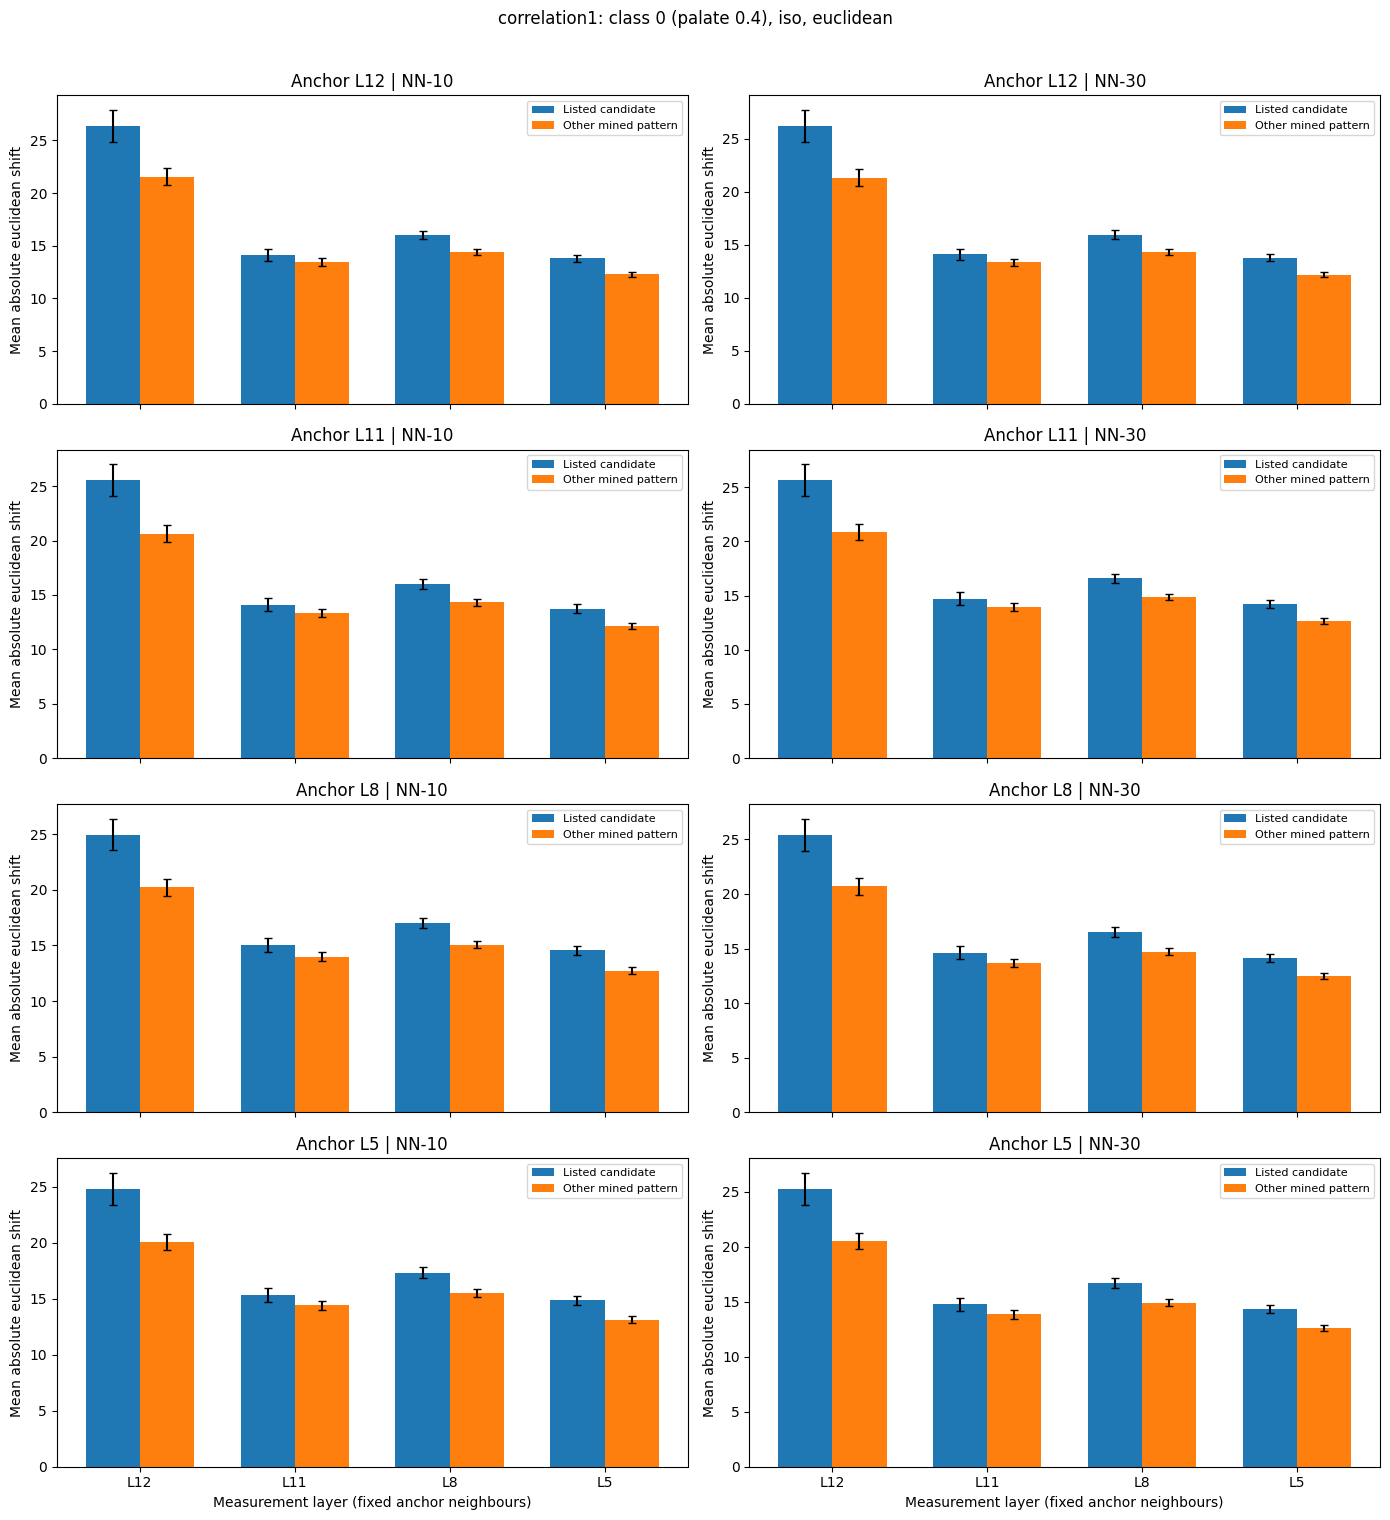

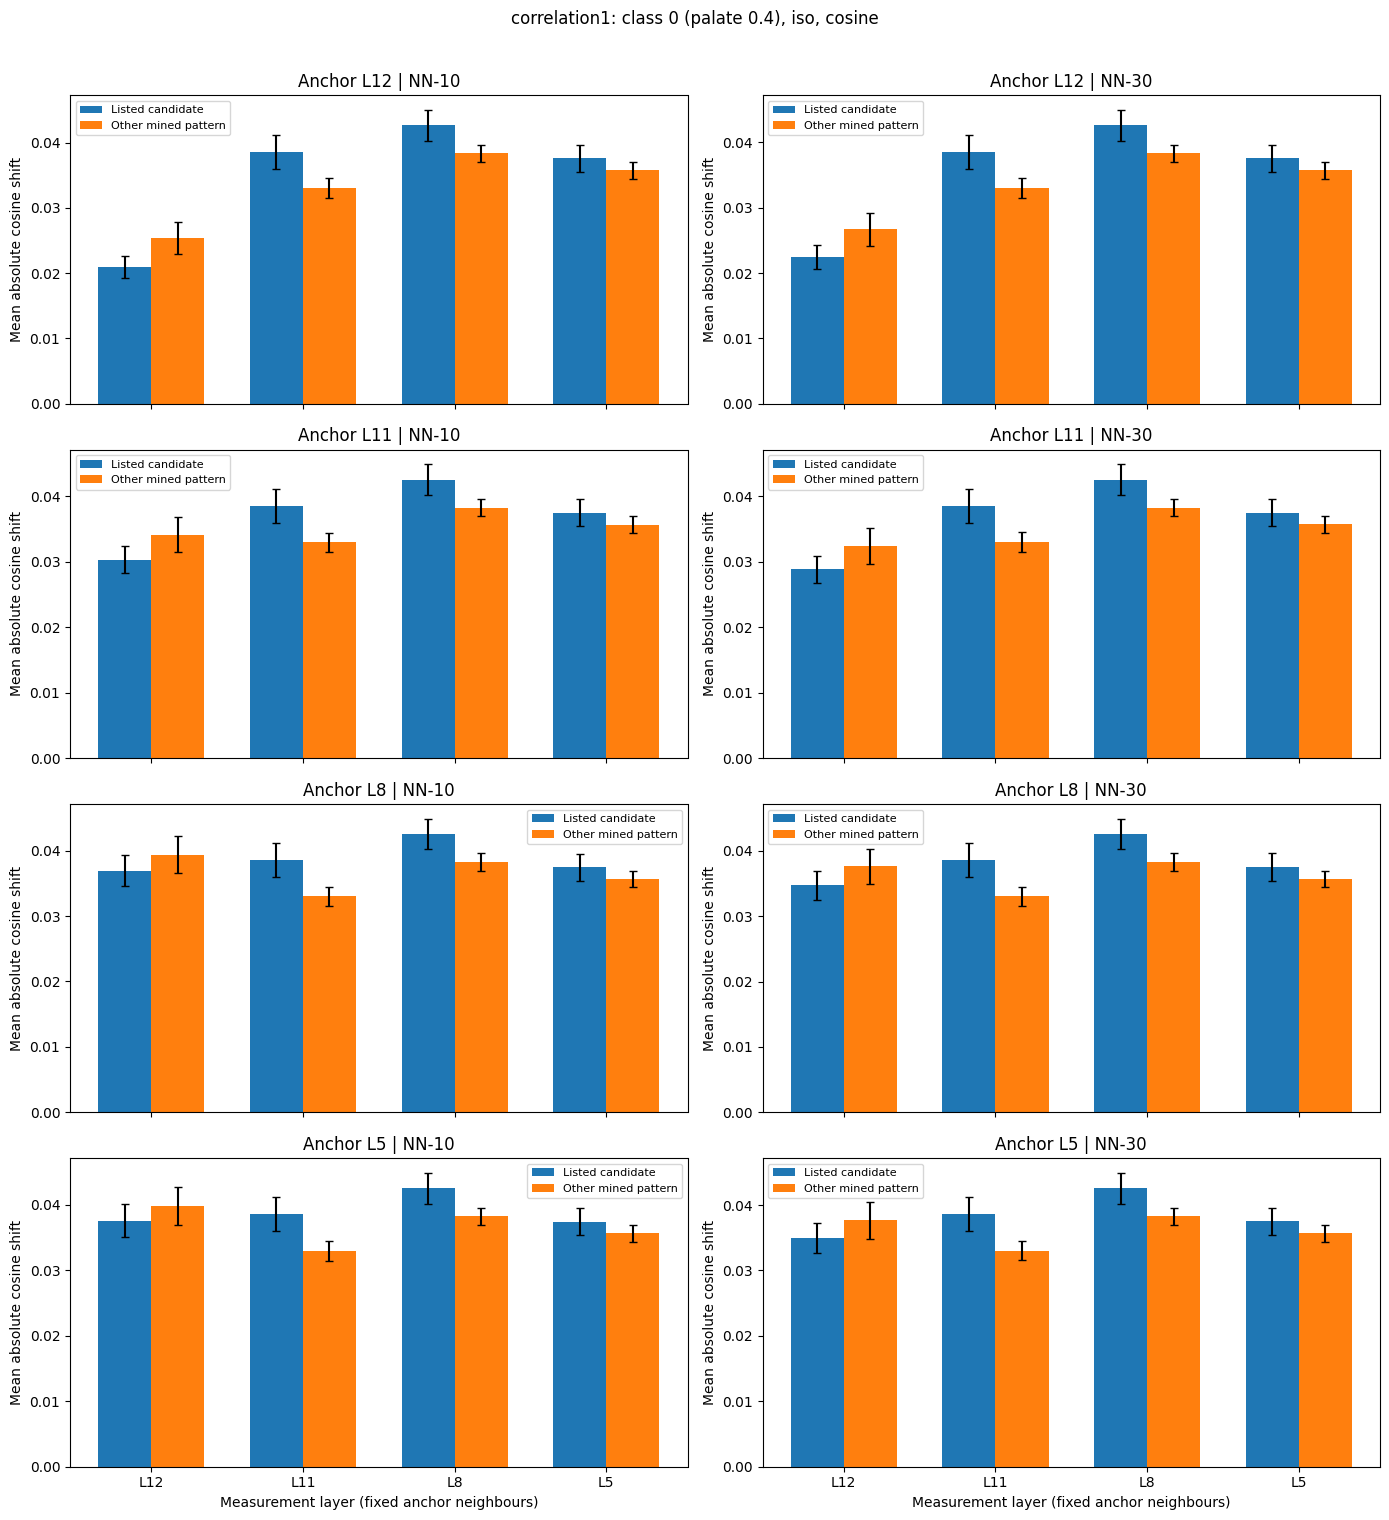

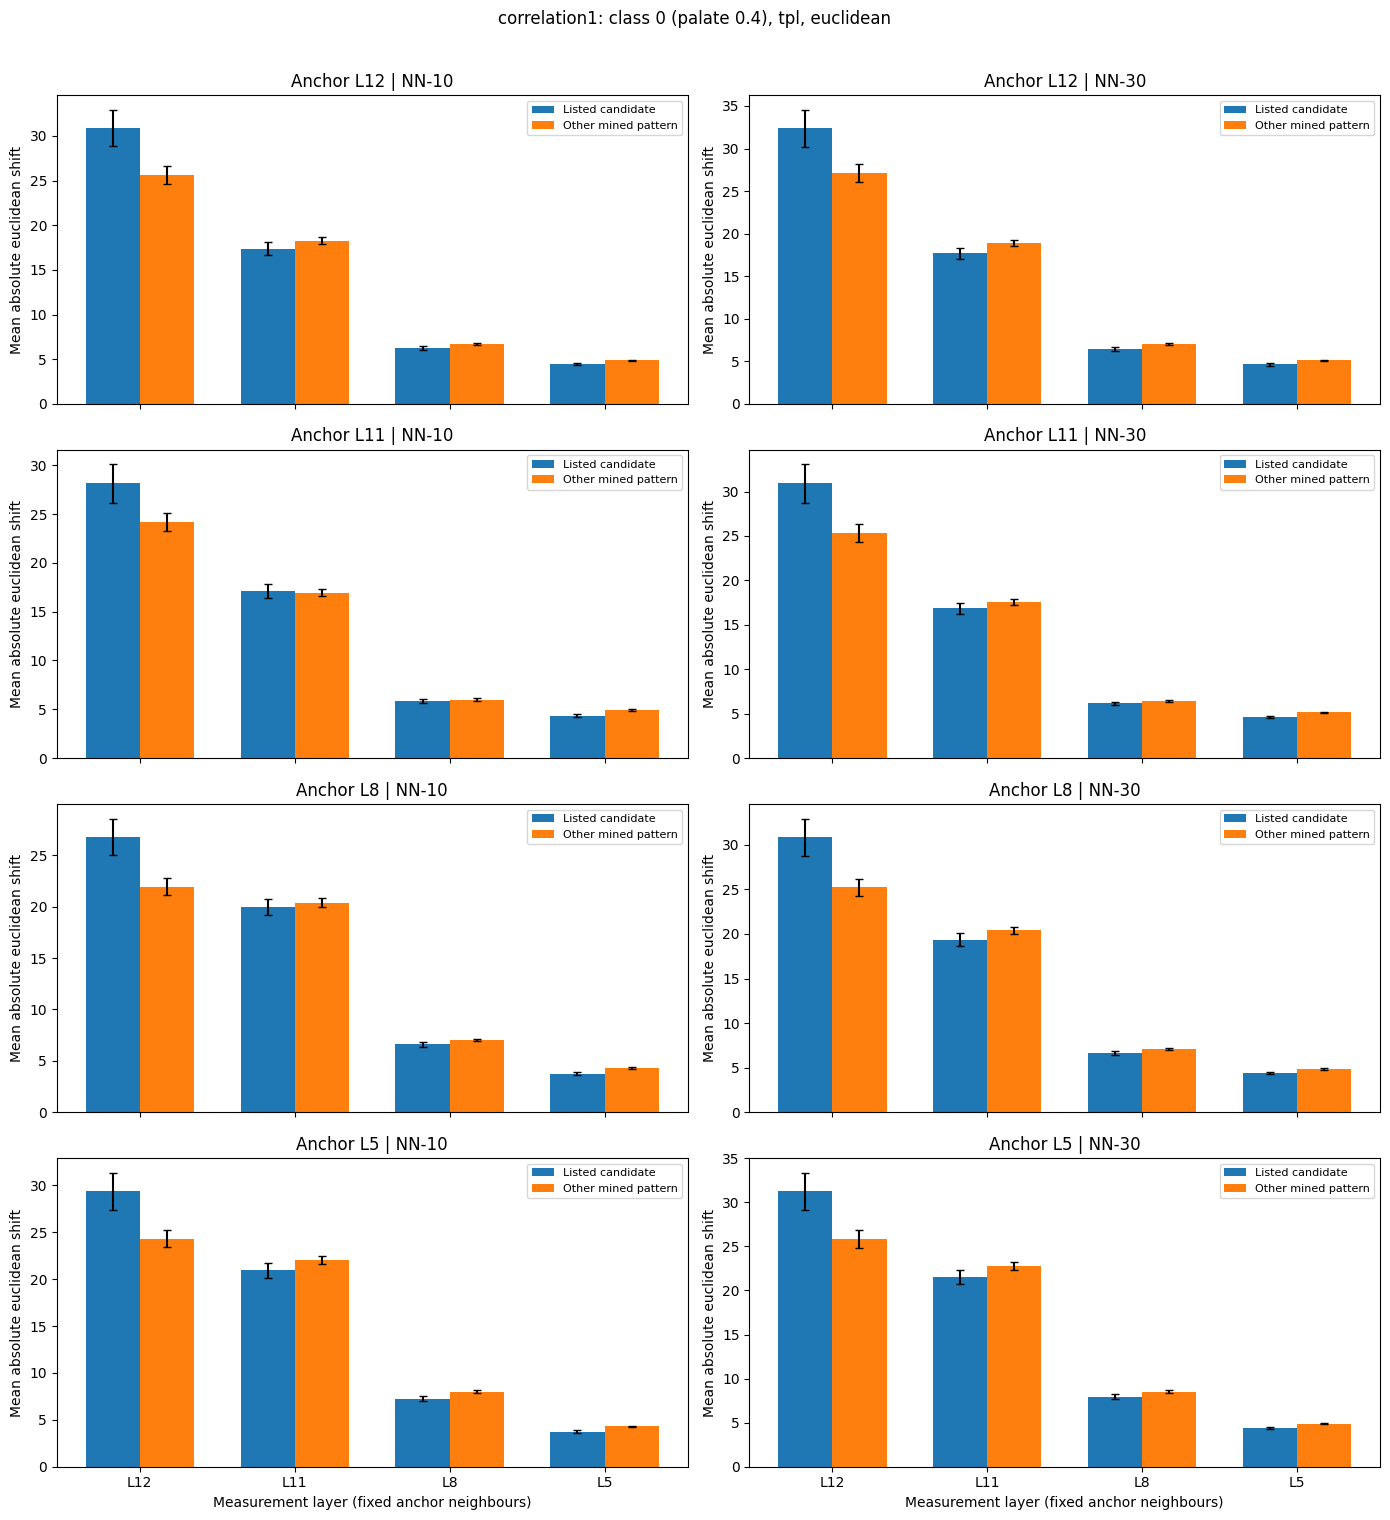

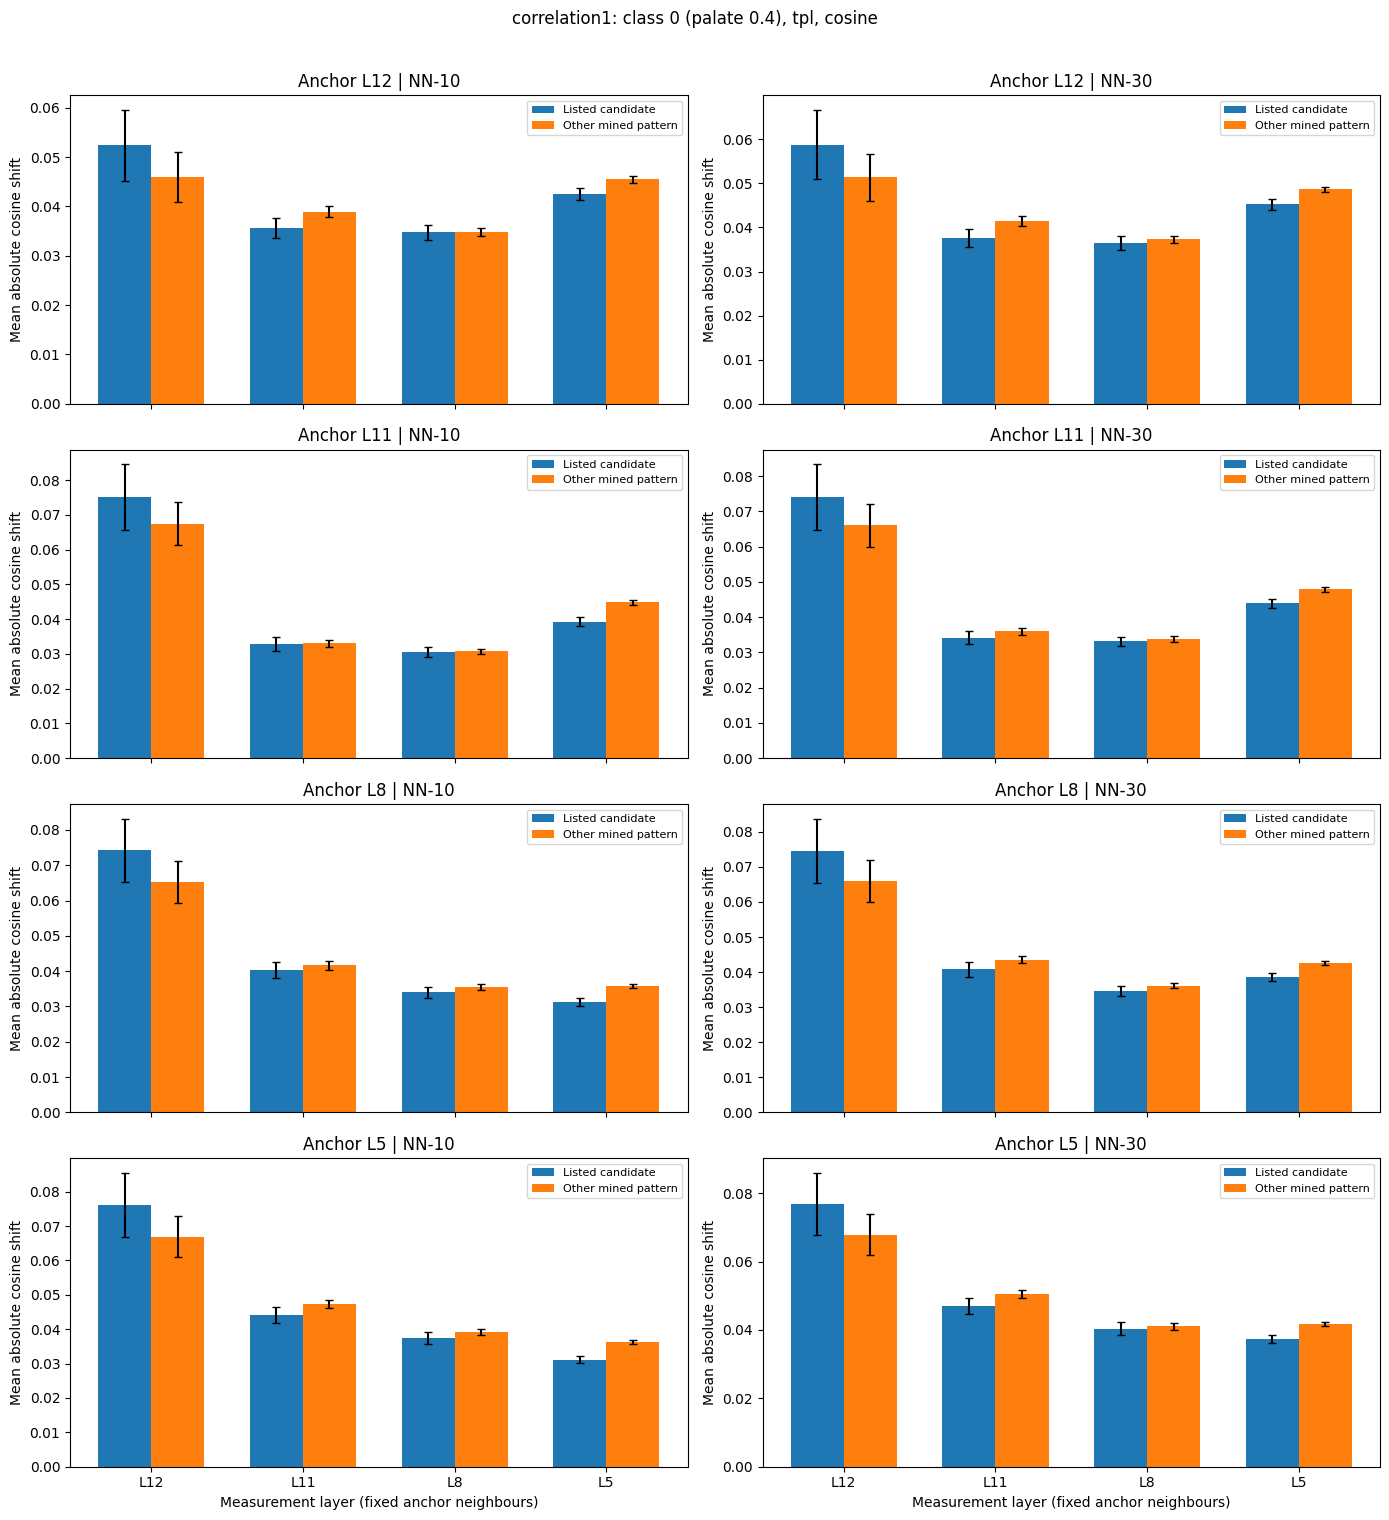

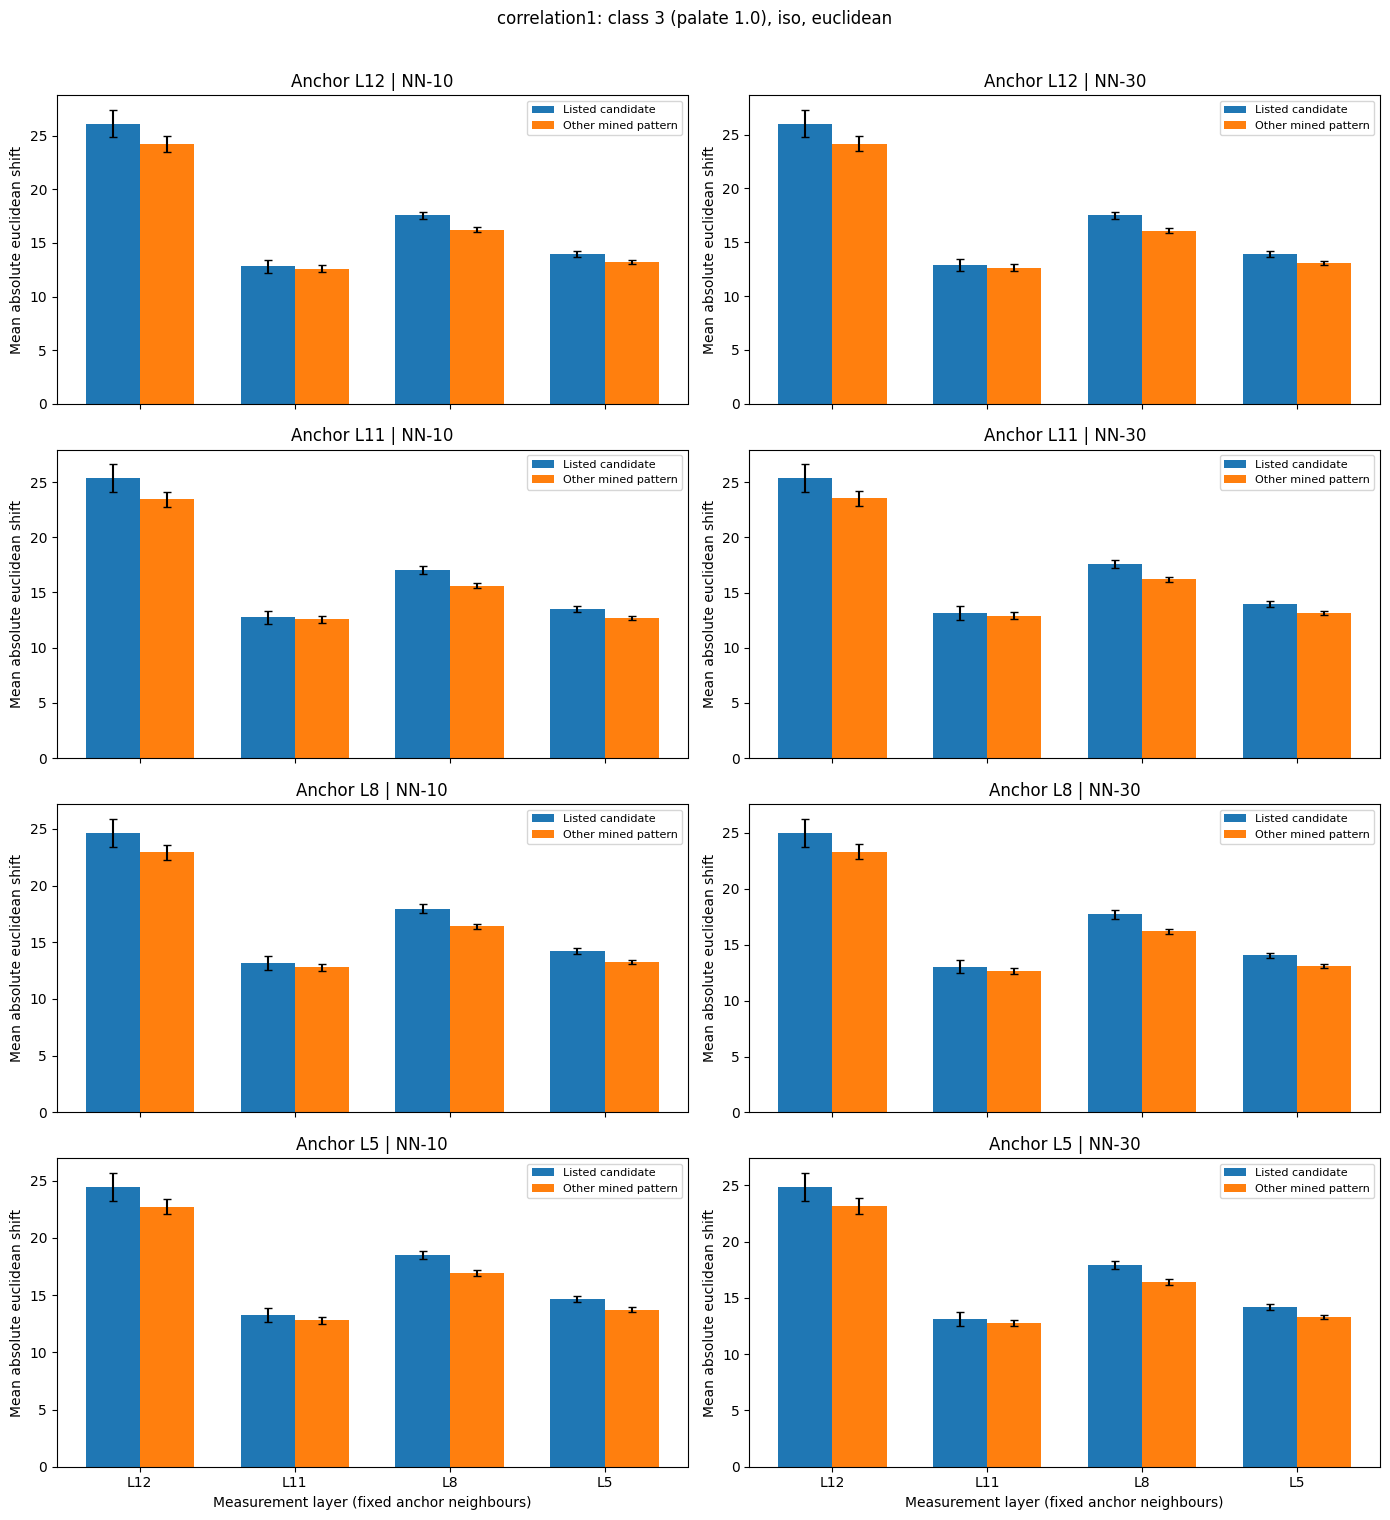

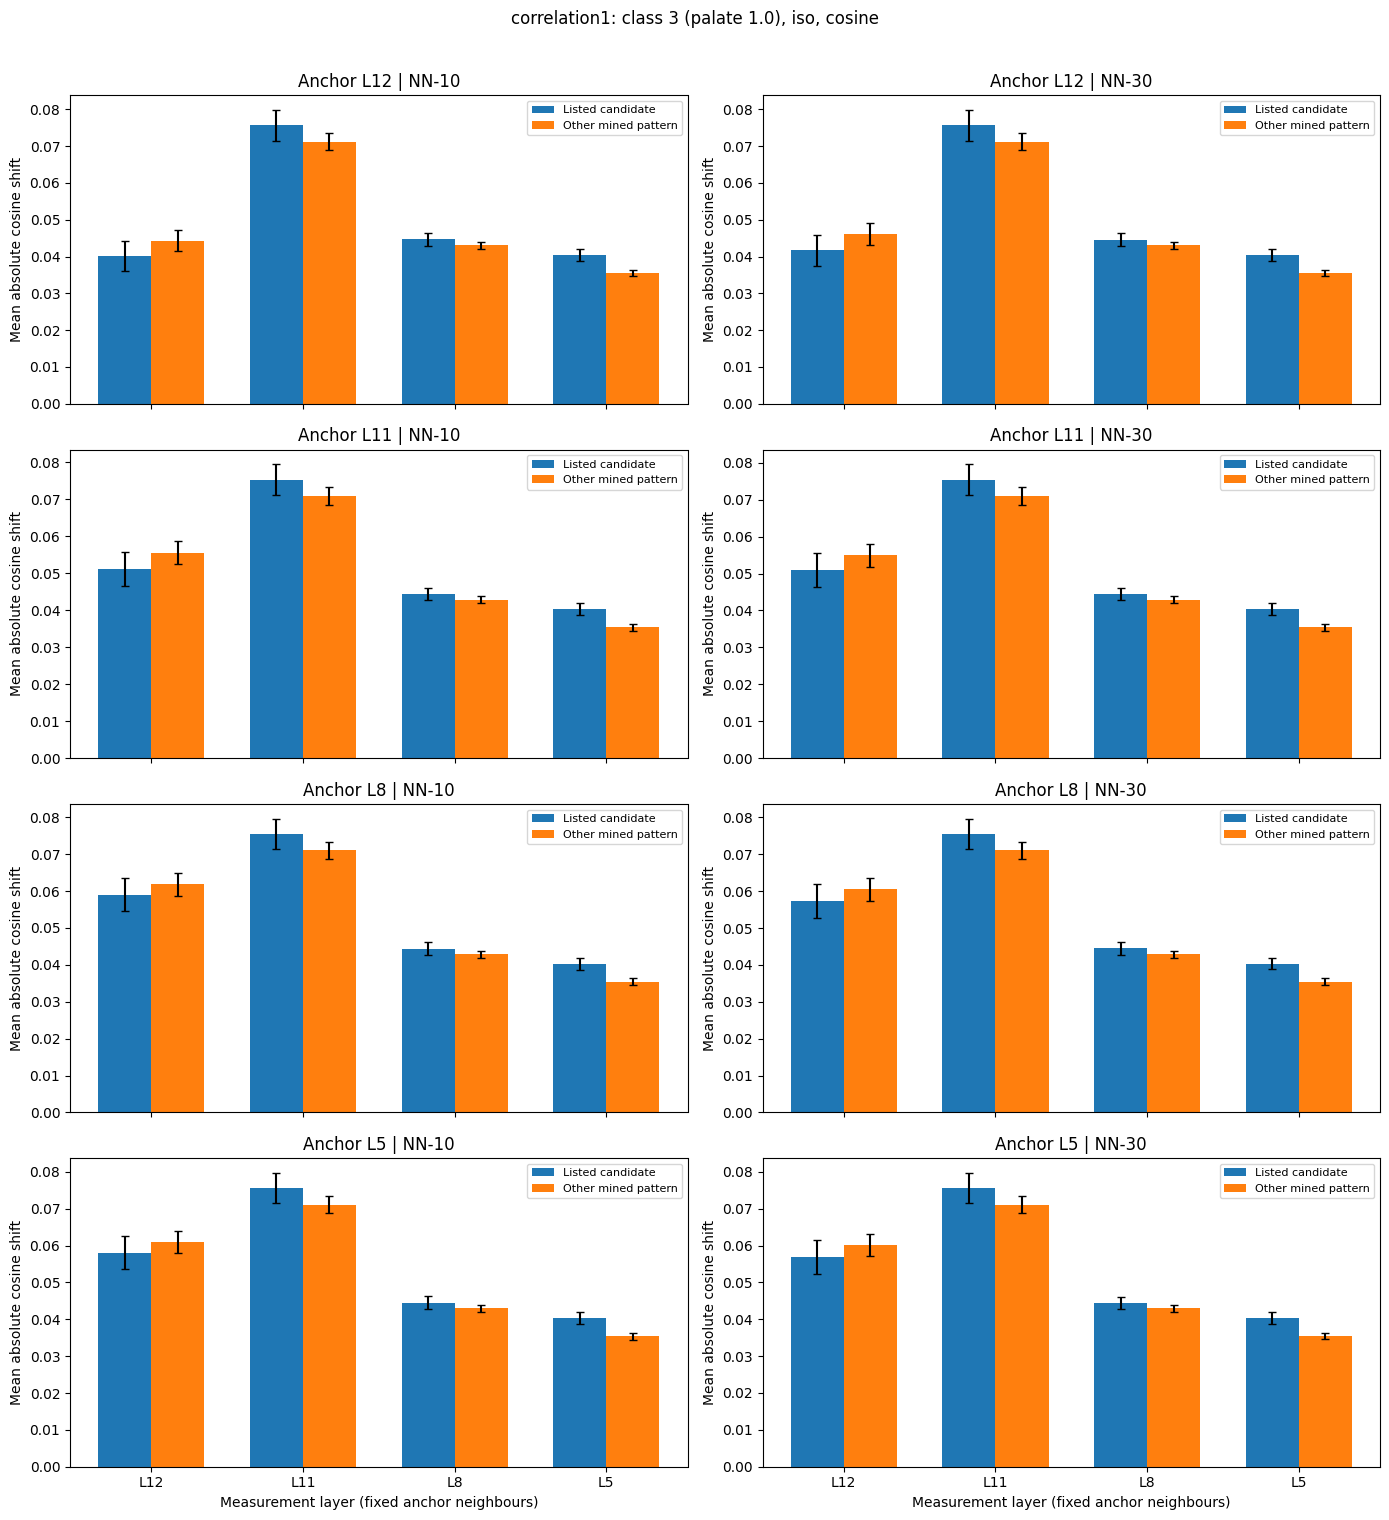

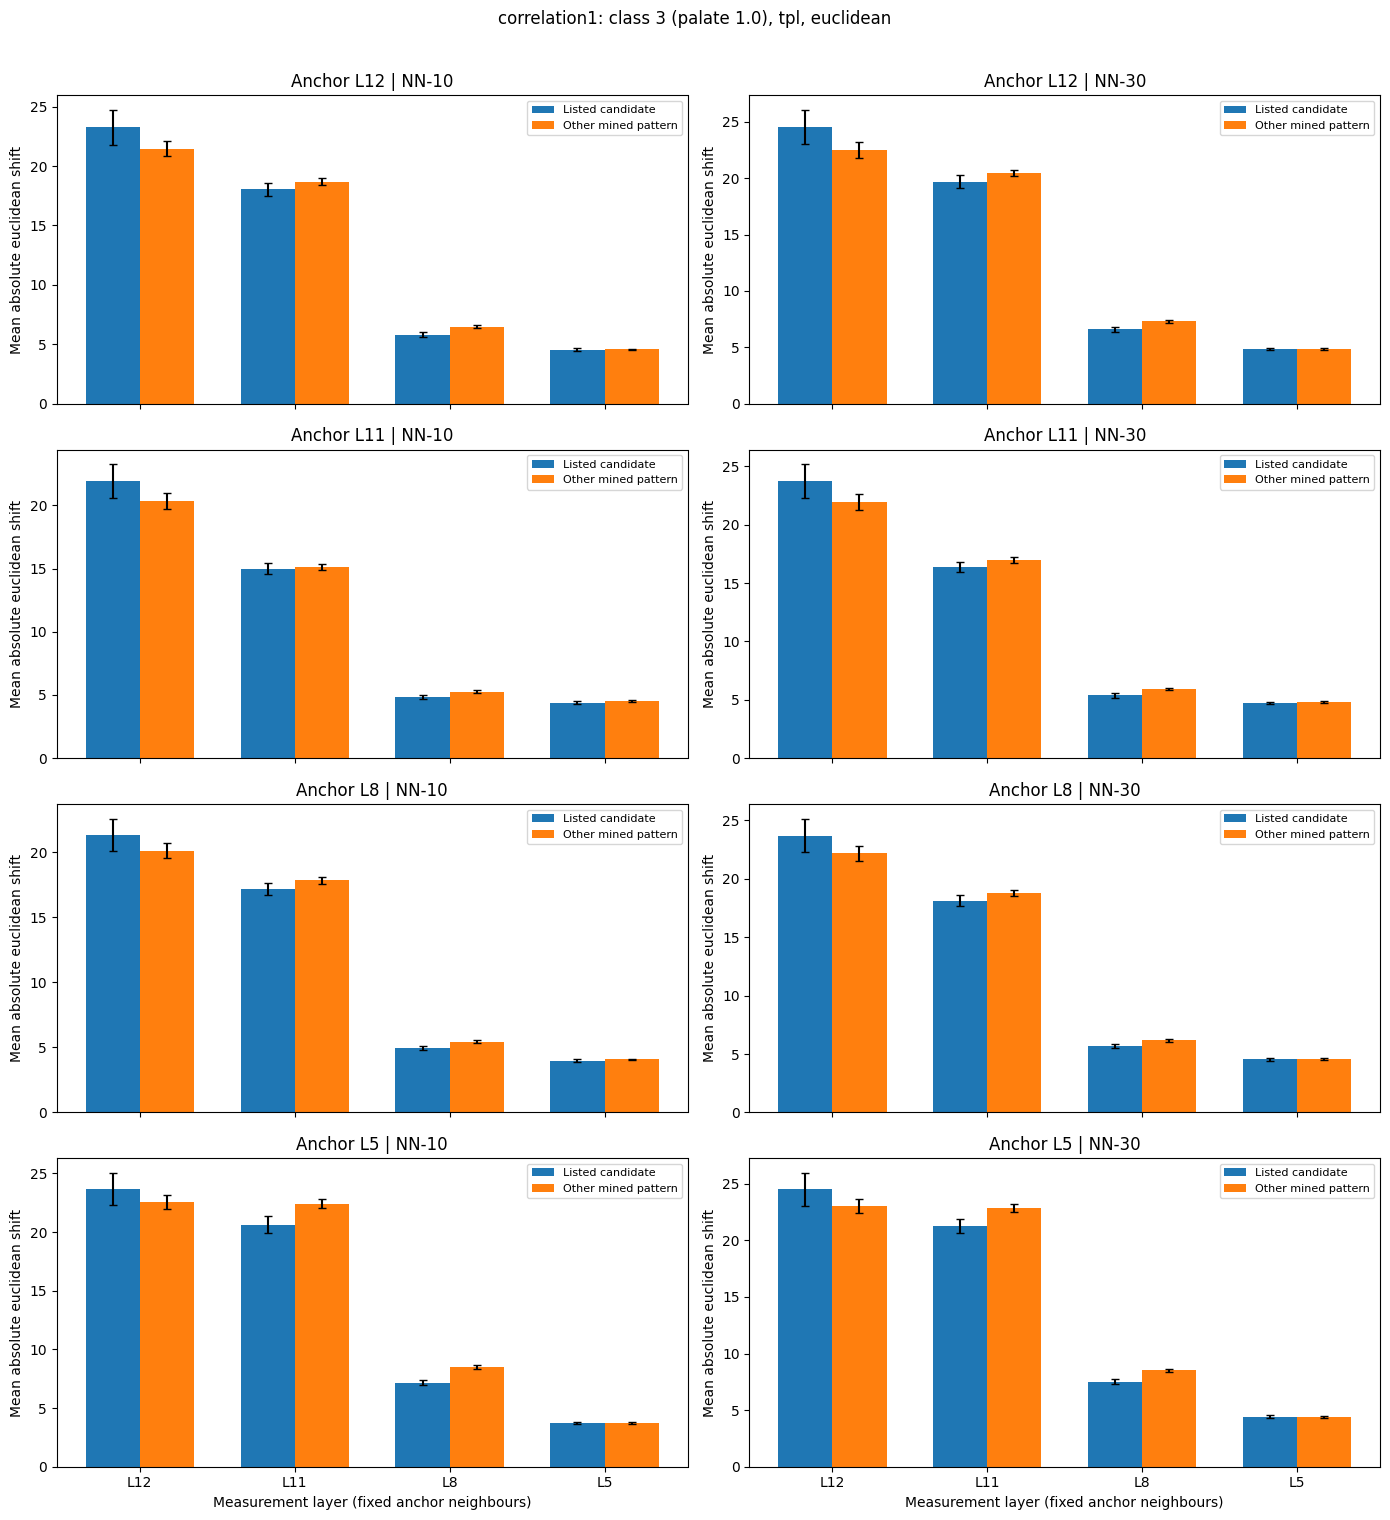

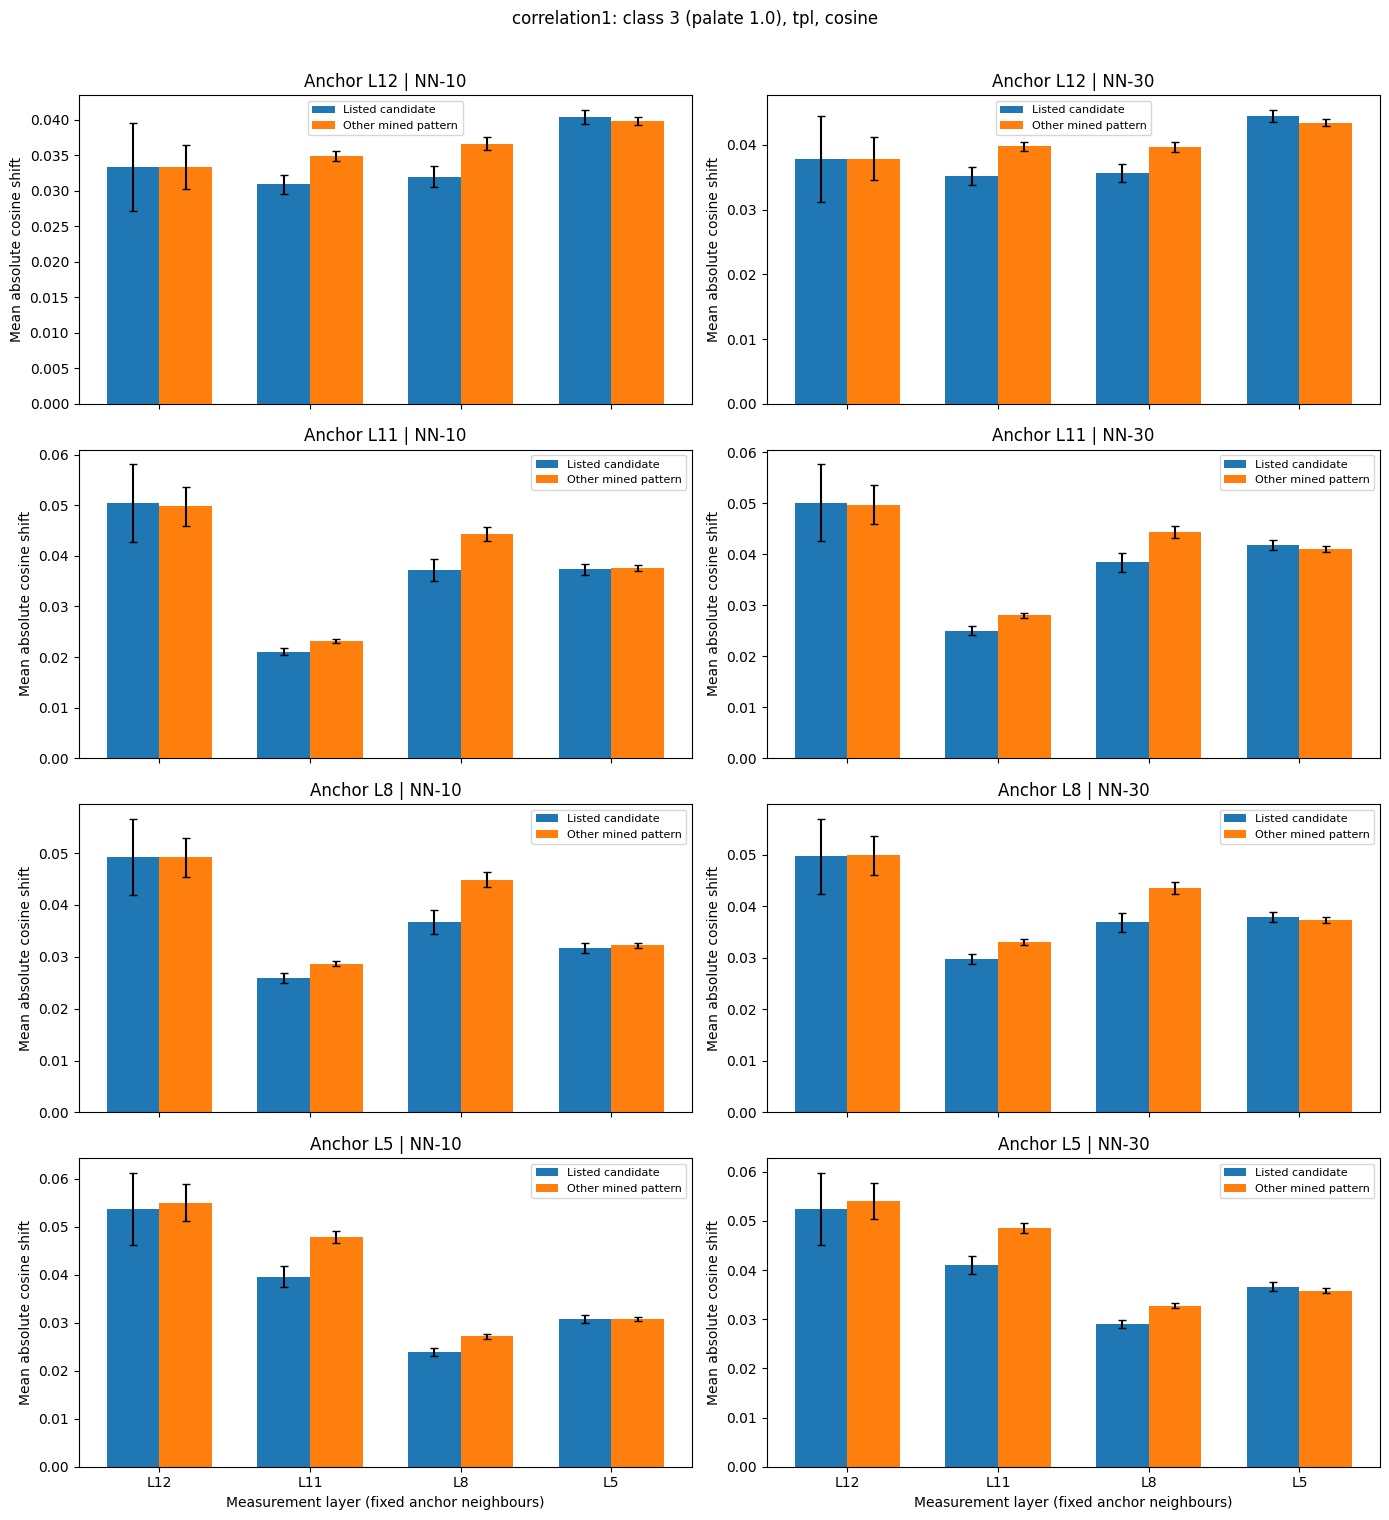

In [48]:
def plot_anchor_shortcut_means(summary, predicted_class, context="iso", metric="euclidean"):
    """Compare pattern-group means across measured layers with fixed FT anchor neighbours."""
    if predicted_class not in SHORTCUT_CANDIDATES_BY_CLASS:
        raise ValueError("No class-specific candidate list exists for this predicted class")
    if context not in NN_CONTEXTS or metric not in ("euclidean", "cosine"):
        raise ValueError("Invalid context or distance metric")

    mean_col = f"mean_delta_{metric}"
    sem_col = f"sem_delta_{metric}"
    fig, axes = plt.subplots(len(ANCHOR_LAYERS), len(NN_K_VALUES), figsize=(14, 15),
                             sharex=True, squeeze=False)
    x = np.arange(len(ANCHOR_LAYERS))
    bar_width = 0.35

    for i, anchor_layer in enumerate(ANCHOR_LAYERS):
        for j, k in enumerate(NN_K_VALUES):
            ax = axes[i, j]
            selected = summary.loc[
                (summary["predicted_class"] == predicted_class)
                & (summary["context"] == context)
                & (summary["anchor_layer"] == anchor_layer)
                & (summary["k"] == k)
            ]
            for offset, group, label in (
                (-bar_width / 2, "listed_candidate", "Listed candidate"),
                (+bar_width / 2, "other_pattern", "Other mined pattern"),
            ):
                group_rows = selected.loc[selected["group"] == group].set_index("layer")
                group_rows = group_rows.reindex(ANCHOR_LAYERS)
                ax.bar(
                    x + offset, group_rows[mean_col].to_numpy(dtype=float), bar_width,
                    yerr=group_rows[sem_col].fillna(0).to_numpy(dtype=float),
                    capsize=3, label=label,
                )
            ax.set_title(f"Anchor L{anchor_layer} | NN-{k}")
            ax.set_ylabel(f"Mean absolute {metric} shift")
            ax.set_xticks(x, [f"L{layer}" for layer in ANCHOR_LAYERS])
            ax.legend(fontsize=8)
            if i == len(ANCHOR_LAYERS) - 1:
                ax.set_xlabel("Measurement layer (fixed anchor neighbours)")

    fig.suptitle(
        f"{EXPERIMENT}: class {predicted_class} (palate {ID_TO_RATING[predicted_class]:.1f}), "
        f"{context}, {metric}", y=1.01
    )
    fig.tight_layout()
    plt.show()
    return fig


# NN-10 and NN-30 appear side-by-side for each anchor in both contexts and classes.
# Error bars are SEM across mined patterns; a single-pattern group has undefined SEM.
for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    for context in NN_CONTEXTS:
        for metric in ("euclidean", "cosine"):
            plot_anchor_shortcut_means(anchor_shortcut_summary_df, class_id, context, metric)


In [49]:
# Top 30 patterns: anchor L12, measurement L12, templated context.
for class_id in (0, 3):
    for k in (10, 30):
        for metric in ("euclidean", "cosine"):
            delta_col = f"mean_abs_{metric}_shift"

            top30 = (
                anchor_shortcut_pattern_df.query(
                    "predicted_class == @class_id and "
                    "anchor_layer == 12 and "
                    "layer == 12 and "
                    "k == @k and "
                    "context == 'tpl'"
                )
                .sort_values(delta_col, ascending=False)
                .head(30)
            )

            print(f"Class {class_id} | NN-{k} | {metric} delta")
            display(top30[
                ["ordered_tokens", "group", "support",
                 "mean_abs_euclidean_shift", "mean_abs_cosine_shift"]
            ])

Class 0 | NN-10 | euclidean delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
40160,"[Ġ., Ġm, Ġ]",other_pattern,0.019608,114.434708,0.493719
7904,"[Ġ., Ġmouth, Ġ]",other_pattern,0.142857,106.884644,0.502131
10720,"[Ġthin, Ġmedium, Ġ., Ġ]",other_pattern,0.016807,103.457436,1.124830
34144,"[Ġ., Ġis, Ġ]",listed_candidate,0.016807,101.487862,0.479831
21792,"[Ġ., ours, Ġ]",other_pattern,0.030812,101.076271,0.611877
15840,"[Ġfaint, Ġ., Ġ]",listed_candidate,0.036415,96.347755,0.523425
17696,"[Ġ., acing, Ġ]",other_pattern,0.028011,94.616905,0.178110
25760,"[Ġ., Ġ-, Ġ]",other_pattern,0.030812,93.326149,1.379039
18720,"[Ġvery, Ġ., Ġmouth, Ġ]",listed_candidate,0.016807,90.999077,0.236113
16224,"[Ġfaint, Ġmouth, Ġ., Ġ]",listed_candidate,0.016807,90.468857,0.419822


Class 0 | NN-10 | cosine delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
25760,"[Ġ., Ġ-, Ġ]",other_pattern,0.030812,93.326149,1.379039
10720,"[Ġthin, Ġmedium, Ġ., Ġ]",other_pattern,0.016807,103.457436,1.124830
13792,"[Ġ., Ġ]",other_pattern,0.445378,82.068405,0.737776
21216,"[Ġ:, Ġ., Ġ]",other_pattern,0.036415,83.006500,0.713786
21792,"[Ġ., ours, Ġ]",other_pattern,0.030812,101.076271,0.611877
15840,"[Ġfaint, Ġ., Ġ]",listed_candidate,0.036415,96.347755,0.523425
7904,"[Ġ., Ġmouth, Ġ]",other_pattern,0.142857,106.884644,0.502131
40160,"[Ġ., Ġm, Ġ]",other_pattern,0.019608,114.434708,0.493719
34144,"[Ġ., Ġis, Ġ]",listed_candidate,0.016807,101.487862,0.479831
13664,"[Ġmalt, Ġ., Ġ]",listed_candidate,0.016807,74.191116,0.439248


Class 0 | NN-30 | euclidean delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
40161,"[Ġ., Ġm, Ġ]",other_pattern,0.019608,109.984520,0.531603
7905,"[Ġ., Ġmouth, Ġ]",other_pattern,0.142857,109.741440,0.543649
21793,"[Ġ., ours, Ġ]",other_pattern,0.030812,108.494156,0.666610
10721,"[Ġthin, Ġmedium, Ġ., Ġ]",other_pattern,0.016807,108.393707,1.163841
15841,"[Ġfaint, Ġ., Ġ]",listed_candidate,0.036415,107.569450,0.555913
34145,"[Ġ., Ġis, Ġ]",listed_candidate,0.016807,107.389252,0.507250
16225,"[Ġfaint, Ġmouth, Ġ., Ġ]",listed_candidate,0.016807,103.280266,0.448216
17697,"[Ġ., acing, Ġ]",other_pattern,0.028011,97.379112,0.204253
30369,"[Ġ., Ġbody, Ġ]",other_pattern,0.019608,96.041718,0.252573
18721,"[Ġvery, Ġ., Ġmouth, Ġ]",listed_candidate,0.016807,95.023598,0.263297


... (6 outputs left out)

Class 3 | NN-30 | euclidean delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
66849,"[Ġ., Ġi, Ġ]",listed_candidate,0.021073,132.227005,1.083850
73569,"[Ġis, Ġ., Ġmouth, Ġ]",listed_candidate,0.013410,112.224014,0.506603
69345,"[Ġ., Ġmouth, Ġ]",other_pattern,0.105364,109.741440,0.543649
93409,"[Ġ., Ġtexture, Ġ]",other_pattern,0.013410,97.165131,0.336976
106593,"[Ġtan, Ġ., Ġ]",other_pattern,0.011494,96.090286,0.713509
67873,"[Ġ,, Ġmouth, Ġ]",other_pattern,0.011494,95.422981,0.248198
78049,"[Ġstout, Ġ., Ġ]",other_pattern,0.013410,92.282387,0.612339
90401,"[Ġ., Ġmedium, Ġ]",other_pattern,0.024904,90.958656,0.384778
61345,"[Ġaroma, Ġ., Ġ]",listed_candidate,0.065134,88.923172,0.321285
57505,"[Ġ:, Ġmouth, Ġ]",other_pattern,0.013410,88.097023,0.336275


Class 3 | NN-30 | cosine delta


,ordered_tokens,group,support,mean_abs_euclidean_shift,mean_abs_cosine_shift
74529,"[Ġ``, Ġ]",other_pattern,0.021073,29.037205,1.087525
66849,"[Ġ., Ġi, Ġ]",listed_candidate,0.021073,132.227005,1.083850
57633,"[Ġ., Ġ:, Ġ]",other_pattern,0.019157,80.682373,1.037918
92129,"[Ġarom, Ġ., Ġ]",other_pattern,0.015326,87.138260,0.792803
51617,"[Ġ., Ġ]",other_pattern,0.413793,83.746895,0.778289
73441,"[Ġis, Ġ., Ġ]",listed_candidate,0.022989,84.040436,0.778056
106593,"[Ġtan, Ġ., Ġ]",other_pattern,0.011494,96.090286,0.713509
78049,"[Ġstout, Ġ., Ġ]",other_pattern,0.013410,92.282387,0.612339
109537,"[Ġ-, Ġ., Ġ]",other_pattern,0.015326,56.375420,0.556193
69345,"[Ġ., Ġmouth, Ġ]",other_pattern,0.105364,109.741440,0.543649


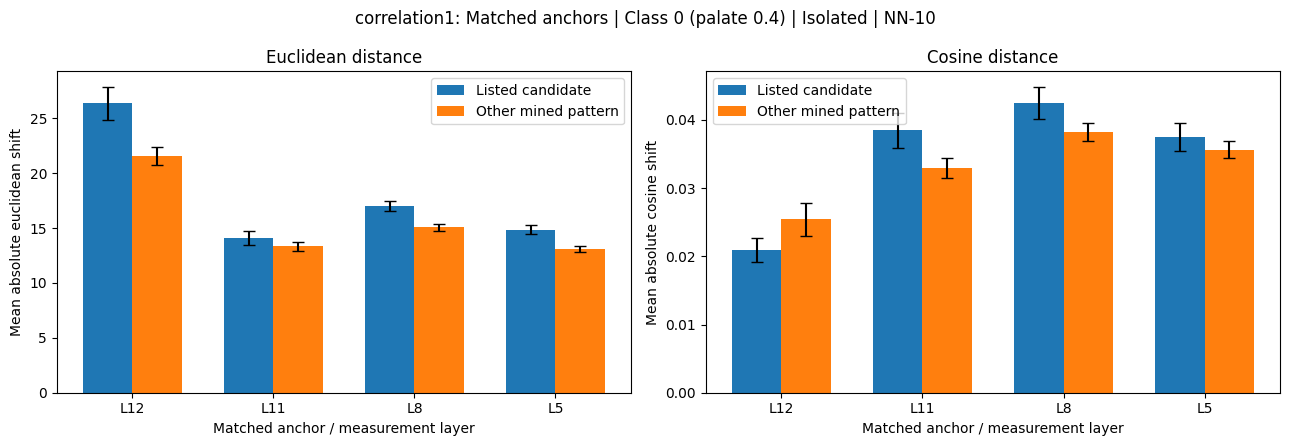

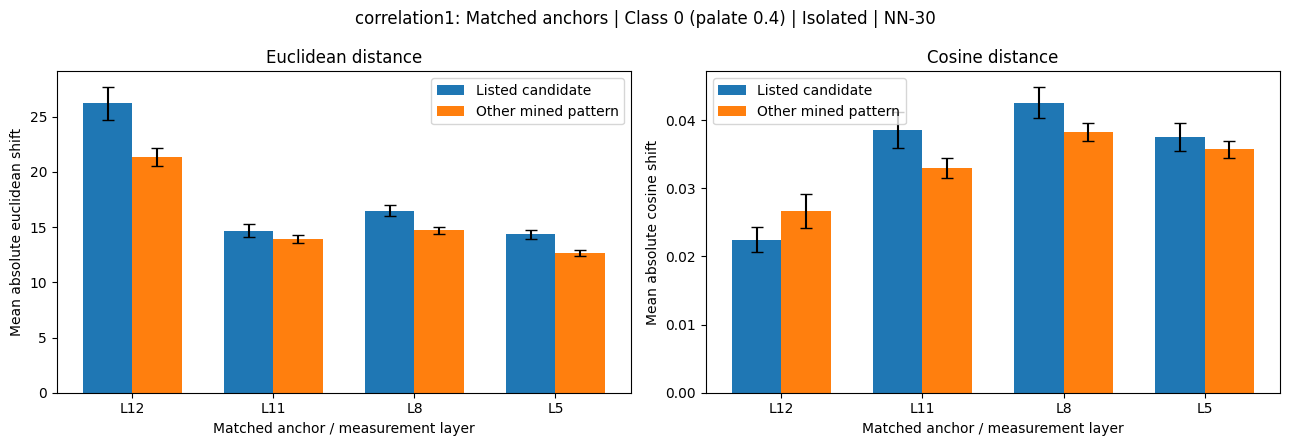

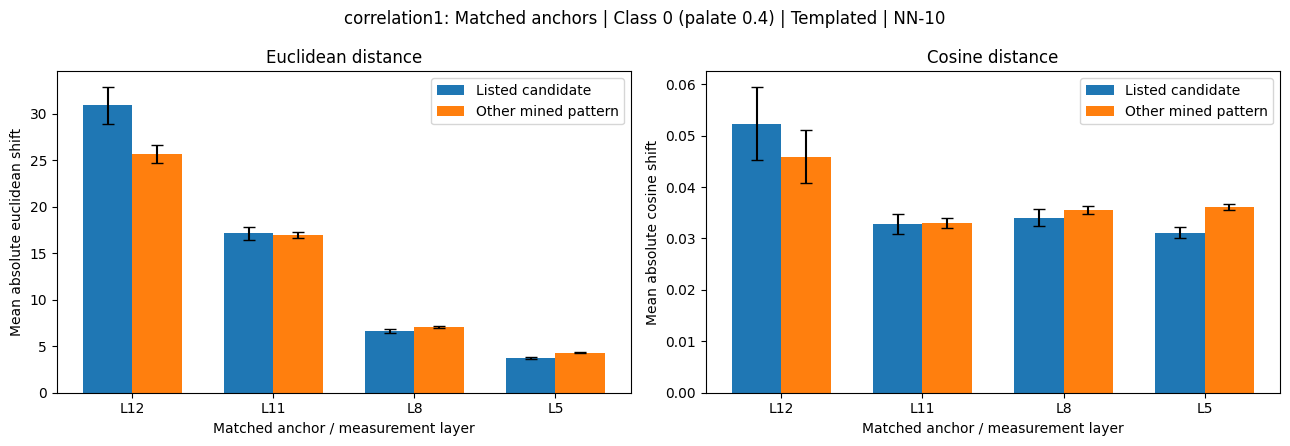

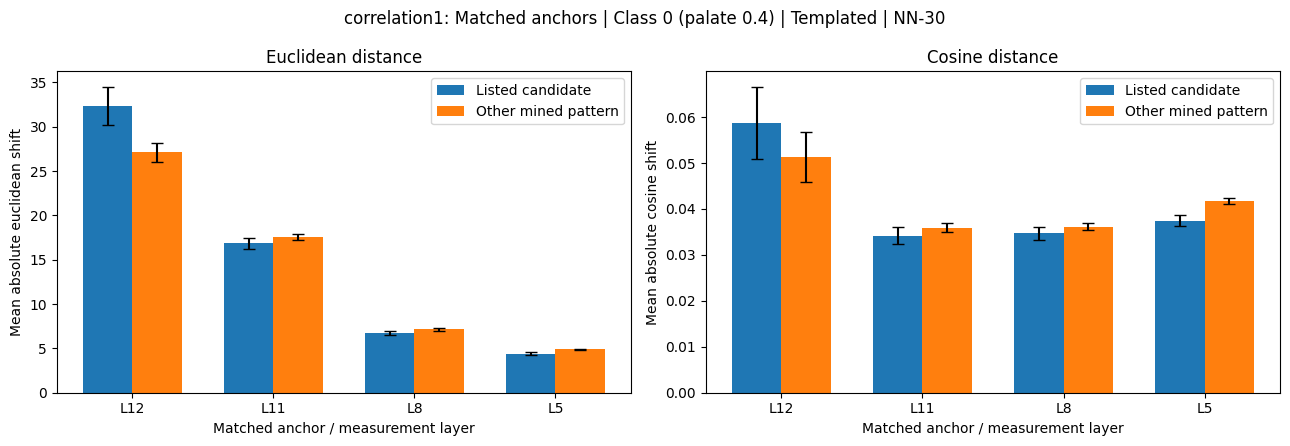

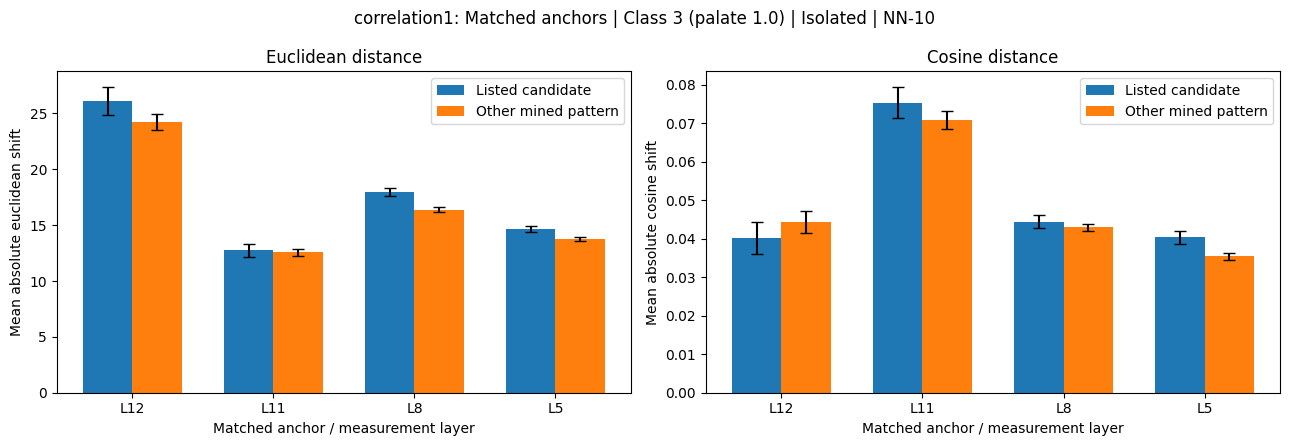

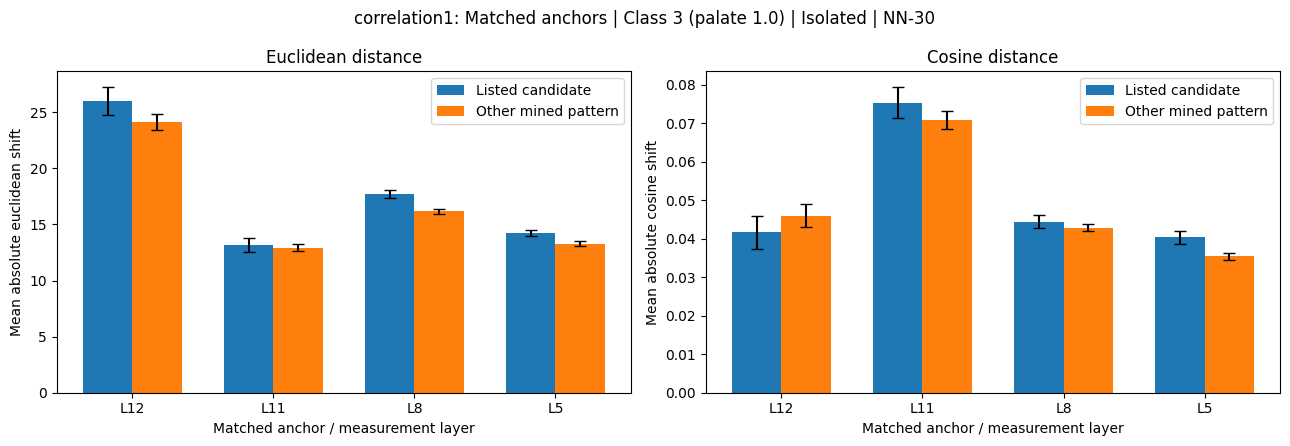

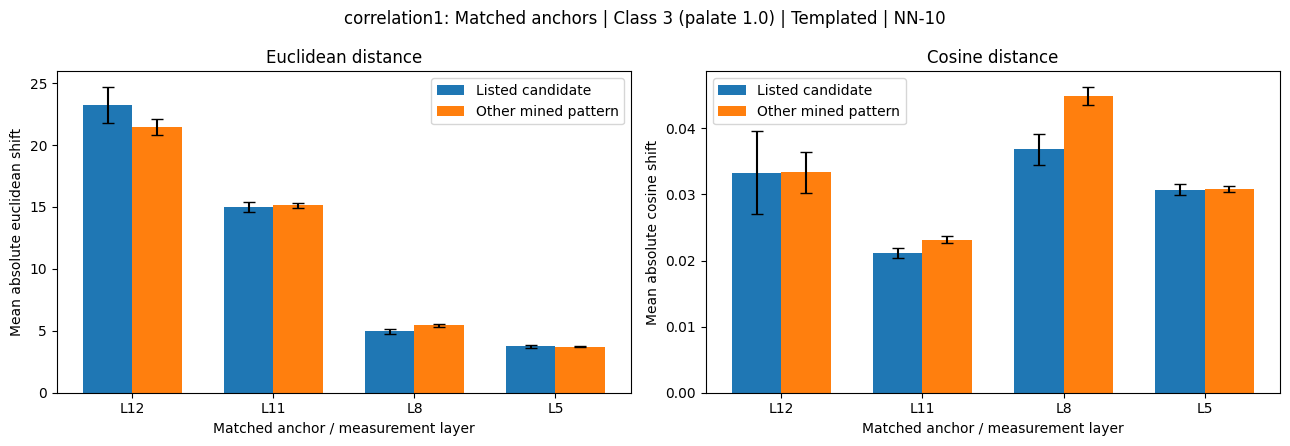

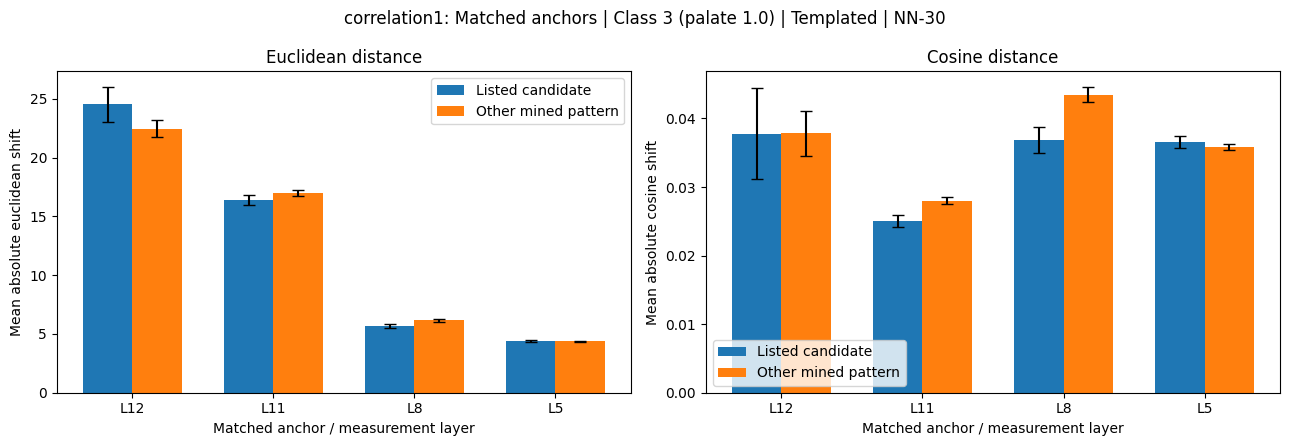

,predicted_class,rating,context,k,anchor_layer,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean,mean_delta_cosine,sem_delta_cosine
30,0,0.4,iso,10,12,12,listed_candidate,157,26.371293,1.516428,0.020925,0.001727
31,0,0.4,iso,10,12,12,other_pattern,491,21.566658,0.795877,0.025401,0.002440
20,0,0.4,iso,10,11,11,listed_candidate,157,14.091835,0.600303,0.038469,0.002589
21,0,0.4,iso,10,11,11,other_pattern,491,13.323231,0.372544,0.032943,0.001486
10,0,0.4,iso,10,8,8,listed_candidate,157,17.012625,0.478688,0.042540,0.002336
...,...,...,...,...,...,...,...,...,...,...,...,...
245,3,1.0,tpl,30,11,11,other_pattern,851,16.980987,0.232436,0.028007,0.000502
234,3,1.0,tpl,30,8,8,listed_candidate,238,5.682322,0.187159,0.036894,0.001883
235,3,1.0,tpl,30,8,8,other_pattern,851,6.169117,0.113054,0.043489,0.001156
224,3,1.0,tpl,30,5,5,listed_candidate,238,4.419964,0.106557,0.036616,0.000878


In [50]:

# ============================================================
# Experiment 3: Matched-anchor summary
# L12->L12, L11->L11, L8->L8, L5->L5
# ============================================================

matched_anchor_summary_df = anchor_shortcut_summary_df.loc[
    anchor_shortcut_summary_df["anchor_layer"]
    == anchor_shortcut_summary_df["layer"]
].copy()


def plot_matched_anchor_summary(
    summary,
    predicted_class,
    context="iso",
    k=10,
):
    """Plot matched-anchor shifts with SEM across patterns."""

    selected = summary.loc[
        (summary["predicted_class"] == predicted_class)
        & (summary["context"] == context)
        & (summary["k"] == k)
    ]

    layer_order = list(ANCHOR_LAYERS)
    x = np.arange(len(layer_order))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for ax, metric in zip(axes, ("euclidean", "cosine")):

        mean_col = f"mean_delta_{metric}"
        sem_col = f"sem_delta_{metric}"

        for offset, group, label in (
            (-width / 2, "listed_candidate", "Listed candidate"),
            (+width / 2, "other_pattern", "Other mined pattern"),
        ):

            group_rows = (
                selected.loc[selected["group"] == group]
                .set_index("anchor_layer")
                .reindex(layer_order)
            )

            means = group_rows[mean_col].to_numpy(dtype=float)
            sems = group_rows[sem_col].fillna(0).to_numpy(dtype=float)

            valid = np.isfinite(means)

            ax.bar(
                (x + offset)[valid],
                means[valid],
                width,
                yerr=sems[valid],
                capsize=4,
                label=label,
            )

        ax.set_xticks(x, [f"L{layer}" for layer in layer_order])
        ax.set_xlabel("Matched anchor / measurement layer")
        ax.set_ylabel(f"Mean absolute {metric} shift")
        ax.set_title(f"{metric.capitalize()} distance")
        ax.legend()

    context_name = "Isolated" if context == "iso" else "Templated"

    fig.suptitle(
        f"{EXPERIMENT}: Matched anchors | "
        f"Class {predicted_class} "
        f"(palate {ID_TO_RATING[predicted_class]:.1f}) | "
        f"{context_name} | NN-{k}"
    )

    fig.tight_layout()
    plt.show()

    return fig


for class_id in SHORTCUT_CANDIDATES_BY_CLASS:
    for context in NN_CONTEXTS:
        for k in NN_K_VALUES:
            plot_matched_anchor_summary(
                matched_anchor_summary_df,
                predicted_class=class_id,
                context=context,
                k=k,
            )

display(
    matched_anchor_summary_df.sort_values(
        ["predicted_class", "context", "k", "anchor_layer"],
        ascending=[True, True, True, False],
    )
)


In [51]:
result = matched_anchor_summary_df.query(
    "predicted_class == 0 and context == 'iso' "
    "and k == 10 and anchor_layer == 8 "
    "and layer == 8 and group == 'other_pattern'"
)

print(result[[
    "mean_delta_euclidean",
    "sem_delta_euclidean"
]].to_string(index=False))

 mean_delta_euclidean  sem_delta_euclidean
             15.05845             0.327331


In [52]:
display(
    anchor_shortcut_summary_df.query(
        "predicted_class == 0 and "
        "context == 'tpl' and "
        "k == 10 and "
        "anchor_layer == layer"
    )[
        ["layer", "group", "n_patterns",
         "mean_delta_euclidean", "sem_delta_euclidean"]
    ]
)

,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean
64,5,listed_candidate,157,3.739353,0.132815
65,5,other_pattern,491,4.317694,0.072999
74,8,listed_candidate,157,6.605241,0.232991
75,8,other_pattern,491,7.036733,0.131043
84,11,listed_candidate,157,17.146377,0.710835
85,11,other_pattern,491,16.938068,0.354310
94,12,listed_candidate,157,30.888394,2.018005
95,12,other_pattern,491,25.640875,0.990936


In [53]:
display(
    anchor_shortcut_summary_df.query(
        "predicted_class == 0 and "
        "context == 'tpl' and "
        "k == 10 and "
        "anchor_layer == layer"
    )[
        ["layer", "group", "n_patterns",
         "mean_delta_euclidean", "sem_delta_euclidean"]
    ]
)

,layer,group,n_patterns,mean_delta_euclidean,sem_delta_euclidean
64,5,listed_candidate,157,3.739353,0.132815
65,5,other_pattern,491,4.317694,0.072999
74,8,listed_candidate,157,6.605241,0.232991
75,8,other_pattern,491,7.036733,0.131043
84,11,listed_candidate,157,17.146377,0.710835
85,11,other_pattern,491,16.938068,0.354310
94,12,listed_candidate,157,30.888394,2.018005
95,12,other_pattern,491,25.640875,0.990936
